# Premier League fixture preparation
Combine the two season CSVs, compute pre-match form, verify it, and export separate inputs, targets and benchmark odds.

Run all cells in Python 3.9+. Put the named CSVs next to the notebook or in its `upload/` folder. No third-party packages are required. Add future season files in the configuration cell.

**Availability rule.** The CSVs provide kickoff times but no final-whistle or publication timestamps. This pilot uses only results from earlier calendar dates in the source time convention. This deliberately skips same-day results. Form includes home and away matches and carries over between seasons for teams with recorded history. A team returning to the league may have older recorded matches. Rows with fewer than three prior matches on either side stay in the export with a readiness flag and blank totals on the incomplete side.


In [1]:
from collections import defaultdict
import csv
from datetime import datetime
from pathlib import Path
from xgboost import XGBClassifier

SEASON_FILES = {
    "2023/24": "E 2023 to 2024.csv",
    "2024/25": "E 2024 to 2025.csv",
}
WINDOW = 3
OUTPUT = Path("fixture_outputs")
ODDS_GROUPS = {
    "average_1x2": ("AvgCH", "AvgCD", "AvgCA"),
    "average_total_25": ("AvgC>2.5", "AvgC<2.5"),
    "bet365_1x2": ("B365CH", "B365CD", "B365CA"),
    "bet365_total_25": ("B365C>2.5", "B365C<2.5"),
}
ODDS_COLUMNS = [column for group in ODDS_GROUPS.values() for column in group]

def load_fixtures(season_files):
    fixtures = []
    seen = set()
    for season, filename in season_files.items():
        path = Path(filename)
        if not path.is_file():
            path = Path("upload") / filename
        with path.open(encoding="utf-8-sig", newline="") as stream:
            for line, row in enumerate(csv.DictReader(stream), start=2):
                try:
                    kickoff = datetime.strptime(
                        f"{row['Date']} {row['Time']}", "%d/%m/%Y %H:%M"
                    )
                    home, away = row["HomeTeam"].strip(), row["AwayTeam"].strip()
                    hg, ag = int(row["FTHG"]), int(row["FTAG"])
                    if not home or not away or home == away or min(hg, ag) < 0:
                        raise ValueError("Invalid teams or score")
                    if row["FTR"] != ("H" if hg > ag else "A" if hg < ag else "D"):
                        raise ValueError("Result disagrees with full-time score")
                except (KeyError, ValueError, TypeError, AttributeError) as error:
                    raise ValueError(f"{path}:{line}: {error}") from error
                fixture_id = f"{season}|{home}|{away}"
                if fixture_id in seen:
                    raise ValueError(f"Duplicate fixture: {fixture_id}")
                seen.add(fixture_id)
                fixtures.append(dict(
                    fixture_id=fixture_id, season=season, kickoff=kickoff,
                    home_team=home, away_team=away, home_goals=hg, away_goals=ag,
                    **{column: row.get(column, "") for column in ODDS_COLUMNS}
                ))
    if not fixtures:
        raise ValueError("No fixtures found")
    return sorted(fixtures, key=lambda row: (row["kickoff"], row["fixture_id"]))

fixtures = load_fixtures(SEASON_FILES)
for season in SEASON_FILES:
    print(season, sum(row["season"] == season for row in fixtures), "fixtures")


2023/24 380 fixtures
2024/25 380 fixtures


## Build reusable form features

The function accepts completed history and a separate list of fixtures to forecast. Upcoming fixtures need only the fixture ID, season, kickoff and team names. In a historical replay, pass the same fixture list in both arguments. The date check excludes the target fixture and all later results.


In [2]:
def build_form_features(completed, targets, window=3):
    if not isinstance(window, int) or window < 1:
        raise ValueError("The form window must be a positive integer")

    history = defaultdict(list)
    for match in sorted(completed, key=lambda row: row["kickoff"]):
        hg, ag = match["home_goals"], match["away_goals"]
        for side, scored, conceded in (("home", hg, ag), ("away", ag, hg)):
            points = 3 if scored > conceded else 1 if scored == conceded else 0
            history[match[f"{side}_team"]].append(
                (match["kickoff"].date(), points, scored, conceded)
            )

    rows = []
    for match in sorted(targets, key=lambda row: (row["kickoff"], row["fixture_id"])):
        features = {key: match[key] for key in (
            "fixture_id", "season", "kickoff", "home_team", "away_team"
        )}
        for side in ("home", "away"):
            prior = [
                entry for entry in history[match[f"{side}_team"]]
                if entry[0] < match["kickoff"].date()
            ][-window:]
            features[f"{side}_prior_count_capped"] = len(prior)
            for index, name in enumerate(("points", "goals_scored", "goals_conceded"), 1):
                features[f"{side}_{name}_last_{window}"] = (
                    sum(entry[index] for entry in prior) if len(prior) == window else None
                )
        features["form_ready"] = all(
            features[f"{side}_prior_count_capped"] == window for side in ("home", "away")
        )
        rows.append(features)
    return rows

features = build_form_features(fixtures, fixtures, WINDOW)
print(sum(row["form_ready"] for row in features), "fixtures with full form for both teams")
print(features[0])


720 fixtures with full form for both teams
{'fixture_id': '2023/24|Burnley|Man City', 'season': '2023/24', 'kickoff': datetime.datetime(2023, 8, 11, 20, 0), 'home_team': 'Burnley', 'away_team': 'Man City', 'home_prior_count_capped': 0, 'home_points_last_3': None, 'home_goals_scored_last_3': None, 'home_goals_conceded_last_3': None, 'away_prior_count_capped': 0, 'away_points_last_3': None, 'away_goals_scored_last_3': None, 'away_goals_conceded_last_3': None, 'form_ready': False}


## Create outcomes and keep benchmark odds separate

Join exports on `fixture_id`. The modelling inputs are the lagged totals. Identifiers, kickoff, season, and readiness fields are included for tracking and chronological splits. The benchmark file retains raw closing odds as supplied. Exact capture timestamps are unavailable in these files. Score labels and odds are in separate exports.


In [3]:
def make_targets(match):
    hg, ag = match["home_goals"], match["away_goals"]
    return {
        "fixture_id": match["fixture_id"],
        "home_goals": hg,
        "away_goals": ag,
        "target_1x2": "H" if hg > ag else "A" if hg < ag else "D",
        "target_over_25": int(hg + ag >= 3),
        "target_btts": int(hg > 0 and ag > 0),
    }

targets = [make_targets(match) for match in fixtures]
odds = [
    {key: match[key] for key in ["fixture_id", *ODDS_COLUMNS]}
    for match in fixtures
]


## Verify on real fixtures

For Arsenal vs Man United on 3 September 2023, Arsenal's prior scores from its perspective were 2–1 vs Nott'm Forest, 1–0 vs Crystal Palace and 2–2 vs Fulham. That gives **7 points, 5 scored, 3 conceded**.

For Man City vs Fulham on 2 September 2023, City's prior scores were 3–0 vs Burnley, 1–0 vs Newcastle and 2–1 vs Sheffield United. That gives **9 points, 6 scored, 1 conceded**. The checks below also perturb a result and verify its features are unchanged while a later fixture's features respond.


In [4]:
assert [r["fixture_id"] for r in features] == [r["fixture_id"] for r in targets]
assert [r["fixture_id"] for r in features] == [r["fixture_id"] for r in odds]
by_id = {row["fixture_id"]: row for row in features}
if WINDOW == 3 and "2023/24" in SEASON_FILES:
    for fixture_id, expected in {
        "2023/24|Arsenal|Man United": (7, 5, 3),
        "2023/24|Man City|Fulham": (9, 6, 1),
    }.items():
        actual = tuple(by_id[fixture_id][f"home_{name}_last_3"] for name in (
            "points", "goals_scored", "goals_conceded"
        ))
        assert actual == expected, (fixture_id, actual, expected)
        print(f"Manual check passed: {fixture_id} → {actual}")

changed_match = fixtures[0]
changed_history = [dict(changed_match, home_goals=changed_match["home_goals"] + 1), *fixtures[1:]]
changed_features = build_form_features(changed_history, fixtures, WINDOW)
same_date = changed_match["kickoff"].date()
assert all(
    original == changed
    for original, changed in zip(features, changed_features)
    if original["kickoff"].date() == same_date
)
if WINDOW == 3 and "2023/24" in SEASON_FILES:
    assert any(original != changed for original, changed in zip(features, changed_features))
print("Result-change check passed: own and same-day features are unchanged.")


Manual check passed: 2023/24|Arsenal|Man United → (7, 5, 3)
Manual check passed: 2023/24|Man City|Fulham → (9, 6, 1)
Result-change check passed: own and same-day features are unchanged.


In [5]:
OUTPUT.mkdir(exist_ok=True)
for filename, rows in (
    ("prematch_features.csv", features),
    ("match_targets.csv", targets),
    ("benchmark_odds.csv", odds),
):
    path = OUTPUT / filename
    with path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    print(f"{path}: {len(rows)} rows")


fixture_outputs/prematch_features.csv: 760 rows
fixture_outputs/match_targets.csv: 760 rows
fixture_outputs/benchmark_odds.csv: 760 rows


**Soccer forecasting · baseline pilot**

Compare historical frequencies, Dixon–Coles, XGBoost and available market-average closing odds. Run the preparation notebook first, then run this notebook from the same working directory.

Dependencies: numpy pandas scipy. Install xgboost in the same kernel for the ML comparison. If XGBoost is missing, the notebook explicitly skips it and runs the other benchmarks.

Protocol: Fit on 2023/24 and evaluate on 2024/25, on common fixtures with complete three-match form for both teams. Dixon–Coles can use all completed training scores because it does not need form features. XGBoost uses only the six lagged totals. Evaluation uses the preparation notebook's as-of-date form, which may incorporate completed earlier pilot fixtures. Parameters are fixed before evaluation. This is an exploratory pilot. Reserve a later unseen period for the final study.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import poisson

ROOT = Path("fixture_outputs")
features = pd.read_csv(ROOT / "prematch_features.csv", parse_dates=["kickoff"])
targets = pd.read_csv(ROOT / "match_targets.csv")
odds = pd.read_csv(ROOT / "benchmark_odds.csv")
for frame in (targets, odds):
    assert set(frame.fixture_id) == set(features.fixture_id), "Fixture IDs differ between exports"

data = (features.merge(targets, on="fixture_id", validate="one_to_one")
        .merge(odds, on="fixture_id", validate="one_to_one")
        .sort_values("kickoff"))
train = data.loc[data.season.eq("2023/24")].copy()
fit = train.loc[train.form_ready].copy()
pilot = data.loc[data.season.eq("2024/25") & data.form_ready].copy()
assert len(fit) and len(pilot) and train.kickoff.max() < pilot.kickoff.min()

FORM = [f"{side}_{stat}_last_3" for side in ("home", "away")
        for stat in ("points", "goals_scored", "goals_conceded")]
assert fit[FORM].notna().all().all() and pilot[FORM].notna().all().all()
MARKETS = {
    "1X2": ("target_1x2", ["H", "D", "A"], ["AvgCH", "AvgCD", "AvgCA"]),
    "O/U 2.5": ("target_over_25", [0, 1], ["AvgC<2.5", "AvgC>2.5"]),
    "BTTS": ("target_btts", [0, 1], []),
}
print(f"Training scores: {len(train)} | Training with form: {len(fit)} | Pilot: {len(pilot)}")

Training scores: 380 | Training with form: 349 | Pilot: 371


**Dixon–Coles score model**

Fit attack and defensive weakness for each training team, a common scoring intercept, home advantage, and the low-score dependence parameter. Attack and defence effects are centered for identifiability. The pilot uses equal match weights. Teams absent from the training season receive league-average effects. The feasible range for the dependence parameter keeps the four low-score correction factors positive for every trained or neutral team pairing.

In [7]:
teams = sorted(set(train.home_team) | set(train.away_team))
lookup = {team: i for i, team in enumerate(teams)}
n = len(teams)

def team_ids(series):
    return np.array([lookup.get(team, n) for team in series], dtype=int)

def unpack(parameters):
    attack = parameters[:n]
    defence = parameters[n:2*n]
    attack = np.r_[attack - attack.mean(), 0.]
    defence = np.r_[defence - defence.mean(), 0.]
    intercept, advantage, dependence = parameters[-3:]
    max_base = np.exp(intercept + attack.max() + defence.max())
    max_home = max_base * np.exp(advantage)
    lower = -0.99 / max(max_home, max_base)
    upper = 0.99 * min(1., 1. / (max_home * max_base))
    rho = dependence * (upper if dependence >= 0 else -lower)
    return attack, defence, intercept, advantage, rho

def rates(parameters, home, away):
    attack, defence, intercept, advantage, rho = unpack(parameters)
    return (np.exp(intercept + advantage + attack[home] + defence[away]),
            np.exp(intercept + attack[away] + defence[home]), rho)

def correction(h, a, home_rate, away_rate, rho):
    return np.select(
        [(h == 0) & (a == 0), (h == 0) & (a == 1),
         (h == 1) & (a == 0), (h == 1) & (a == 1)],
        [1-home_rate*away_rate*rho, 1+home_rate*rho,
         1+away_rate*rho, 1-rho], default=1.)

home, away = team_ids(train.home_team), team_ids(train.away_team)
h, a = train.home_goals.to_numpy(), train.away_goals.to_numpy()

def loss(parameters):
    hr, ar, rho = rates(parameters, home, away)
    log_probability = (poisson.logpmf(h, hr) + poisson.logpmf(a, ar)
                       + np.log(correction(h, a, hr, ar, rho)))
    return -log_probability.sum()

# Fix one free coordinate per centered effect and constrain the dependence coordinate.
bounds = ([(-2., 2.)] * (n-1) + [(0., 0.)]) * 2 + [(-2., 2.), (-2., 2.), (-1., 1.)]
result = minimize(loss, np.zeros(2*n+3), bounds=bounds, method="L-BFGS-B")
if not result.success:
    raise RuntimeError(result.message)

def score_probabilities(frame):
    hr, ar, rho = rates(result.x, team_ids(frame.home_team), team_ids(frame.away_team))
    max_goals = max(10, int(poisson.ppf(1-1e-10, max(hr.max(), ar.max()))))
    h_grid, a_grid = np.ogrid[:max_goals+1, :max_goals+1]
    hr, ar = hr[:, None, None], ar[:, None, None]
    grid = (poisson.pmf(h_grid, hr) * poisson.pmf(a_grid, ar)
            * correction(h_grid, a_grid, hr, ar, rho))
    mass = grid.sum(axis=(1, 2), keepdims=True)
    assert np.allclose(mass, 1, atol=1e-8, rtol=0)
    grid /= mass
    groups = {
        "1X2": [h_grid > a_grid, h_grid == a_grid, h_grid < a_grid],
        "O/U 2.5": [h_grid+a_grid < 3, h_grid+a_grid >= 3],
        "BTTS": [(h_grid == 0) | (a_grid == 0), (h_grid > 0) & (a_grid > 0)],
    }
    return {name: np.column_stack([grid[:, mask].sum(axis=1) for mask in masks])
            for name, masks in groups.items()}

dc = score_probabilities(pilot)
print(f"Dixon–Coles fitted. Dependence rho = {unpack(result.x)[-1]:.4f}")
print("Neutral effects used for:", sorted((set(pilot.home_team) | set(pilot.away_team)) - set(teams)))

Dixon–Coles fitted. Dependence rho = -0.0201
Neutral effects used for: ['Ipswich', 'Leicester', 'Southampton']


**Fit the remaining models and score the pilot**

Class order is H/D/A for 1X2, Under/Over for totals, and No/Yes for BTTS. Normalize inverse closing odds to sum to one. When odds are incomplete, compare all models on the common odds-covered subset and report its size. The odds archive has no exact snapshot timestamps, so this is a closing-market comparison. Lower log loss and Brier are better. Brier sums squared errors across classes, including both classes in binary markets. Compare scores within a market.

In [8]:
scores = []
predictions = []

def evaluate(market, model, sample, probability, labels, fixtures):
    assert np.isfinite(probability).all() and (probability >= 0).all()
    assert np.allclose(probability.sum(axis=1), 1)
    actual = np.eye(probability.shape[1])[labels]
    true_probability = probability[np.arange(len(labels)), labels]
    scores.append(dict(
        market=market, model=model, sample=sample, fixtures=len(labels),
        log_loss=-np.log(np.clip(true_probability, 1e-15, 1)).mean(),
        brier=np.square(probability-actual).sum(axis=1).mean(),
        accuracy=(probability.argmax(axis=1) == labels).mean(),
    ))
    for fixture_id, observed, vector in zip(fixtures, labels, probability):
        for outcome, p in enumerate(vector):
            predictions.append(dict(fixture_id=fixture_id, market=market,
                                    model=model, sample=sample,
                                    outcome=MARKETS[market][1][outcome],
                                    probability=p, observed=int(outcome == observed)))

for market, (target, classes, odds_columns) in MARKETS.items():
    encoding = {label: i for i, label in enumerate(classes)}
    y_fit = fit[target].map(encoding).to_numpy(dtype=int)
    y_pilot = pilot[target].map(encoding).to_numpy(dtype=int)
    counts = np.bincount(y_fit, minlength=len(classes))
    if np.any(counts == 0):
        raise ValueError(f"Training class missing in {market}")
    forecasts = {
        "Historical frequency": np.tile(counts/counts.sum(), (len(pilot), 1)),
        "Dixon–Coles": dc[market],
    }
    if XGBClassifier is not None:
        model = XGBClassifier(
            n_estimators=100, max_depth=2, learning_rate=0.05,
            random_state=42, n_jobs=1,
            eval_metric="mlogloss" if len(classes) > 2 else "logloss",
        )
        model.fit(fit[FORM], y_fit)
        assert np.array_equal(model.classes_, np.arange(len(classes)))
        forecasts["XGBoost"] = model.predict_proba(pilot[FORM])

    for name, probability in forecasts.items():
        evaluate(market, name, "All pilot", probability, y_pilot, pilot.fixture_id)
    if odds_columns:
        prices = pilot[odds_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
        valid = (np.isfinite(prices) & (prices > 1)).all(axis=1)
        if valid.any():
            inverse = 1 / prices[valid]
            for name, probability in forecasts.items():
                evaluate(market, name, "Odds matched", probability[valid],
                         y_pilot[valid], pilot.loc[valid, "fixture_id"])
            evaluate(market, "Market average closing", "Odds matched",
                     inverse/inverse.sum(axis=1, keepdims=True),
                     y_pilot[valid], pilot.loc[valid, "fixture_id"])

summary = pd.DataFrame(scores)
print(summary.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
summary.to_csv(ROOT / "pilot_baseline_scores.csv", index=False)
pd.DataFrame(predictions).to_csv(ROOT / "pilot_baseline_predictions.csv", index=False)

 market                  model       sample  fixtures  log_loss  brier  accuracy
    1X2   Historical frequency    All pilot       371    1.0852 0.6587    0.4070
    1X2            Dixon–Coles    All pilot       371    1.0488 0.6327    0.4394
    1X2                XGBoost    All pilot       371    1.0980 0.6624    0.4474
    1X2   Historical frequency Odds matched       371    1.0852 0.6587    0.4070
    1X2            Dixon–Coles Odds matched       371    1.0488 0.6327    0.4394
    1X2                XGBoost Odds matched       371    1.0980 0.6624    0.4474
    1X2 Market average closing Odds matched       371    0.9721 0.5789    0.5526
O/U 2.5   Historical frequency    All pilot       371    0.6969 0.5030    0.5687
O/U 2.5            Dixon–Coles    All pilot       371    0.6798 0.4863    0.5795
O/U 2.5                XGBoost    All pilot       371    0.7065 0.5108    0.5633
O/U 2.5   Historical frequency Odds matched       371    0.6969 0.5030    0.5687
O/U 2.5            Dixon–Col

**Soccer forecasting · probability calibration pilot**

Run the baseline notebook with XGBoost installed to generate predictions, then run this notebook in the same directory. Dependencies: NumPy, pandas and SciPy. The notebook uses the exported fixture-level probabilities and observed outcomes.

Fit a separate temperature for each market and model on the earliest roughly 60% of the 2024/25 pilot fixtures. Compare raw and calibrated forecasts on the remaining fixtures. Keep entire match dates together. The 60% split is unrelated to the project's 60% selection hit-rate target. Because the full season was already reviewed as a baseline pilot, these results are exploratory. Reserve a later unseen period for final testing.

Temperature scaling transforms a probability vector p into softmax(log(p) / T). T > 1 softens the distribution and T < 1 sharpens it. This preserves outcome rankings and normally leaves classification accuracy unchanged. Historical frequencies and normalized closing odds are fixed reference forecasts. Closing odds may have a later information cutoff.

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.special import softmax

ROOT = Path("fixture_outputs")
fixtures = pd.read_csv(ROOT / "prematch_features.csv", parse_dates=["kickoff"])
pred = pd.read_csv(ROOT / "pilot_baseline_predictions.csv", dtype={"outcome": str})
if "XGBoost" not in set(pred.model):
    print("XGBoost forecasts are missing. Rerun the baseline notebook with XGBoost to include them.")

# Prefer the full pilot rows. The odds-matched rows repeat model predictions.
pred = pred.loc[pred["sample"].eq("All pilot") | pred.model.eq("Market average closing")].copy()
dates = fixtures.set_index("fixture_id", verify_integrity=True).kickoff.dt.normalize()
pred["date"] = pred.fixture_id.map(dates)
if pred.empty or pred.date.isna().any():
    raise ValueError("Prediction export is empty or contains unknown fixture IDs")
fixture_dates = pred[["fixture_id", "date"]].drop_duplicates().sort_values("date")
if fixture_dates.date.nunique() < 2:
    raise ValueError("At least two match dates are required")
target_index = min(int(0.60 * len(fixture_dates)), len(fixture_dates)-1)
cutoff = min(fixture_dates.date.iloc[target_index], fixture_dates.date.unique()[-1])
pred["fit_calibrator"] = pred.date.lt(cutoff)
if pred.fit_calibrator.nunique() != 2:
    raise ValueError("The date split leaves an empty period")
print("Evaluation starts:", pd.Timestamp(cutoff).date())
print(pred.groupby("fit_calibrator").fixture_id.nunique().rename(
    index={True: "Calibration fixtures", False: "Evaluation fixtures"}
).to_string())

Evaluation starts: 2025-02-01
fit_calibrator
Evaluation fixtures     151
Calibration fixtures    220


**Fit on earlier forecasts and evaluate on later fixtures**

Log loss measures the probability assigned to the observed outcome. Brier score sums squared errors across outcomes. For reliability checks, the export reports the mean predicted probability and observed event rate in fixed bins, separately for each outcome. Read both values alongside the bin count. Restrict direct bookmaker comparisons to markets with the same evaluation fixture count and coverage.

In [10]:
MARKETS = {"1X2": ["H", "D", "A"], "O/U 2.5": ["0", "1"], "BTTS": ["0", "1"]}
CALIBRATE = {"XGBoost", "Dixon–Coles"}
scores, bins = [], []

def log_loss(probability, actual):
    return -np.log(np.clip(probability[actual == 1], 1e-15, 1)).mean()

def scale(probability, temperature):
    return softmax(np.log(np.clip(probability, 1e-15, 1)) / temperature, axis=1)

for (market, model), group in pred.groupby(["market", "model"]):
    classes = MARKETS[market]
    index = ["date", "fixture_id"]
    raw = group.pivot(index=index, columns="outcome", values="probability")[classes]
    actual = group.pivot(index=index, columns="outcome", values="observed")[classes].reindex(raw.index)
    p, y = raw.to_numpy(), actual.to_numpy()
    if (not np.isfinite(p).all() or (p < 0).any()
            or not np.allclose(p.sum(axis=1), 1)
            or not np.isin(y, [0, 1]).all() or not (y.sum(axis=1) == 1).all()):
        raise ValueError(f"Invalid probabilities or outcomes for {market}, {model}")
    early = raw.index.get_level_values("date") < cutoff
    if not (~early).any():
        continue
    versions = [("Raw", 1., p[~early])]
    if model in CALIBRATE:
        if not early.any() or (y[early].sum(axis=0) == 0).any():
            raise ValueError(f"Calibration period lacks outcomes for {market}, {model}")
        result = minimize_scalar(
            lambda log_t: log_loss(scale(p[early], np.exp(log_t)), y[early]),
            bounds=(np.log(0.25), np.log(4.0)), method="bounded",
        )
        if not result.success:
            raise RuntimeError(result.message)
        temperature = np.exp(result.x)
        versions.append(("Temperature scaled", temperature, scale(p[~early], temperature)))

    observed = y[~early]
    for version, temperature, forecast in versions:
        scores.append(dict(
            market=market, model=model, version=version,
            temperature=temperature, fixtures=len(observed),
            log_loss=log_loss(forecast, observed),
            brier=np.square(forecast-observed).sum(axis=1).mean(),
            accuracy=(forecast.argmax(axis=1) == observed.argmax(axis=1)).mean(),
        ))
        for j, outcome in enumerate(classes):
            bucket = np.minimum((forecast[:, j] * 10).astype(int), 9)
            for b in np.unique(bucket):
                mask = bucket == b
                bins.append(dict(
                    market=market, model=model, version=version, outcome=outcome,
                    bin_lower=b/10, bin_upper=(b+1)/10, count=int(mask.sum()),
                    mean_probability=forecast[mask, j].mean(),
                    observed_frequency=observed[mask, j].mean(),
                ))

summary = pd.DataFrame(scores)
print(summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
summary.to_csv(ROOT / "pilot_calibration_scores.csv", index=False)
pd.DataFrame(bins).to_csv(ROOT / "pilot_reliability_bins.csv", index=False)

 market                  model            version  temperature  fixtures  log_loss  brier  accuracy
    1X2            Dixon–Coles                Raw       1.0000       151    1.0385 0.6246    0.4503
    1X2            Dixon–Coles Temperature scaled       1.4984       151    1.0319 0.6205    0.4503
    1X2   Historical frequency                Raw       1.0000       151    1.0615 0.6433    0.4371
    1X2 Market average closing                Raw       1.0000       151    0.9512 0.5631    0.5894
    1X2                XGBoost                Raw       1.0000       151    1.1071 0.6658    0.4437
    1X2                XGBoost Temperature scaled       1.9287       151    1.0716 0.6463    0.4437
   BTTS            Dixon–Coles                Raw       1.0000       151    0.7369 0.5408    0.4768
   BTTS            Dixon–Coles Temperature scaled       0.9309       151    0.7426 0.5457    0.4768
   BTTS   Historical frequency                Raw       1.0000       151    0.7099 0.5162    0.5232


**Soccer forecasting · TreeSHAP pilot**

Run after fixture preparation. Dependencies: NumPy, pandas, SciPy and XGBoost. This notebook refits the fixed baseline models on 2023/24, estimates temperatures on the earlier 2024/25 pilot block, and explains predictions from 1 February 2025 onward. It uses XGBoost's native exact tree contributions. The six inputs are three-match home and away form totals. Results are exploratory.

For each fixture and output, contributions plus the bias term reconstruct the raw model margin. For binary markets that margin is for the positive outcome. For 1X2 each class has its own margin, and probabilities depend on all three margins. Calibrated probabilities are shown separately. Attributions describe model behaviour and can be shared across related inputs.

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import poisson

ROOT = Path("fixture_outputs")
features = pd.read_csv(ROOT / "prematch_features.csv", parse_dates=["kickoff"])
targets = pd.read_csv(ROOT / "match_targets.csv")
odds = pd.read_csv(ROOT / "benchmark_odds.csv")
for frame in (targets, odds):
    assert set(frame.fixture_id) == set(features.fixture_id), "Fixture IDs differ between exports"

data = (features.merge(targets, on="fixture_id", validate="one_to_one")
        .merge(odds, on="fixture_id", validate="one_to_one")
        .sort_values("kickoff"))
train = data.loc[data.season.eq("2023/24")].copy()
fit = train.loc[train.form_ready].copy()
pilot = data.loc[data.season.eq("2024/25") & data.form_ready].copy()
assert len(fit) and len(pilot) and train.kickoff.max() < pilot.kickoff.min()

FORM = [f"{side}_{stat}_last_3" for side in ("home", "away")
        for stat in ("points", "goals_scored", "goals_conceded")]
assert fit[FORM].notna().all().all() and pilot[FORM].notna().all().all()
MARKETS = {
    "1X2": ("target_1x2", ["H", "D", "A"], ["AvgCH", "AvgCD", "AvgCA"]),
    "O/U 2.5": ("target_over_25", [0, 1], ["AvgC<2.5", "AvgC>2.5"]),
    "BTTS": ("target_btts", [0, 1], []),
}
print(f"Training scores: {len(train)} | Training with form: {len(fit)} | Pilot: {len(pilot)}")

Training scores: 380 | Training with form: 349 | Pilot: 371


In [12]:
from scipy.optimize import minimize_scalar
from scipy.special import softmax, expit
from xgboost import XGBClassifier, DMatrix

cutoff = pd.Timestamp("2025-02-01")
early = pilot.kickoff.lt(cutoff)
assert early.any() and (~early).any()
later = pilot.loc[~early]
print(f"Calibration: {early.sum()} fixtures | Explanation: {len(later)} fixtures")

global_rows, local_rows = [], []
for market, (target, classes, _) in MARKETS.items():
    multiclass = len(classes) > 2
    encoding = {label: index for index, label in enumerate(classes)}
    y = pilot[target].map(encoding).to_numpy(dtype=int)
    model = XGBClassifier(
        n_estimators=100, max_depth=2, learning_rate=0.05,
        random_state=42, n_jobs=1,
        eval_metric="mlogloss" if multiclass else "logloss",
    )
    model.fit(fit[FORM], fit[target].map(encoding).to_numpy(dtype=int))
    assert np.array_equal(model.classes_, np.arange(len(classes)))
    probability = model.predict_proba(pilot[FORM])
    logits = np.log(np.clip(probability, 1e-15, 1))
    def calibration_loss(log_t):
        p = softmax(logits[early] / np.exp(log_t), axis=1)
        return -np.log(p[np.arange(early.sum()), y[early]]).mean()
    optimum = minimize_scalar(calibration_loss, bounds=(np.log(.25), np.log(4)), method="bounded")
    assert optimum.success
    temperature = np.exp(optimum.x)
    raw = probability[~early]
    calibrated = softmax(logits[~early] / temperature, axis=1)

    matrix = DMatrix(later[FORM])
    booster = model.get_booster()
    margins = booster.predict(matrix, output_margin=True, strict_shape=True)
    shap = booster.predict(matrix, pred_contribs=True, approx_contribs=False, strict_shape=True)
    np.testing.assert_allclose(shap.sum(axis=2), margins, atol=2e-5, rtol=1e-5)
    reconstructed = (softmax(margins, axis=1) if multiclass else
                     np.column_stack((expit(-margins[:, 0]), expit(margins[:, 0]))))
    np.testing.assert_allclose(reconstructed, raw, atol=2e-6)
    print(f"{market}: T={temperature:.4f}, max additivity error={abs(shap.sum(axis=2)-margins).max():.2g}")

    explained = classes if multiclass else classes[1:]
    for j, outcome in enumerate(explained):
        for k, feature in enumerate(FORM):
            global_rows.append(dict(market=market, outcome=outcome, feature=feature,
                                    mean_absolute_shap=abs(shap[:, j, k]).mean(),
                                    mean_signed_shap=shap[:, j, k].mean(),
                                    fixtures=len(later)))
    predicted = raw.argmax(axis=1)
    observed = y[~early]
    if multiclass:
        draw = classes.index("D")
        ranked = np.argsort(-raw[:, draw], kind="stable")
        cases = {
            "Highest raw draw probability": ranked[:3],
            "Near median raw draw probability": ranked[len(ranked)//2-1:len(ranked)//2+2],
        }
    else:
        errors = np.flatnonzero(predicted != observed)
        order = np.argsort(-calibrated[errors, predicted[errors]], kind="stable")
        cases = {"Highest calibrated confidence among errors": errors[order[:3]]}

    for case, indices in cases.items():
        for i in indices:
            fixture = later.iloc[i]
            for j, outcome in enumerate(explained):
                outcome_index = classes.index(outcome)
                local_rows.append(dict(
                    market=market, case=case, fixture_id=fixture.fixture_id,
                    kickoff=fixture.kickoff, outcome_explained=outcome,
                    predicted=classes[predicted[i]], observed=classes[observed[i]],
                    raw_probability=raw[i, outcome_index],
                    calibrated_probability=calibrated[i, outcome_index],
                    predicted_calibrated_confidence=calibrated[i, predicted[i]],
                    raw_margin=margins[i, j], base_margin=shap[i, j, -1],
                    **{f"input_{f}": fixture[f] for f in FORM},
                    **{f"shap_{f}": shap[i, j, k] for k, f in enumerate(FORM)},
                ))

Calibration: 220 fixtures | Explanation: 151 fixtures
1X2: T=1.9287, max additivity error=6e-07
O/U 2.5: T=1.8449, max additivity error=3.6e-07
BTTS: T=2.2569, max additivity error=4.8e-07


In [13]:
global_shap = pd.DataFrame(global_rows).sort_values(
    ["market", "outcome", "mean_absolute_shap"], ascending=[True, True, False]
)
local_shap = pd.DataFrame(local_rows)
global_shap.to_csv(ROOT / "pilot_shap_global.csv", index=False)
local_shap.to_csv(ROOT / "pilot_shap_cases.csv", index=False)
print(global_shap.groupby(["market", "outcome"]).head(2).to_string(index=False))
print(local_shap[["market", "case", "fixture_id", "predicted", "observed",
                  "predicted_calibrated_confidence"]].drop_duplicates().to_string(index=False))

 market outcome                    feature  mean_absolute_shap  mean_signed_shap  fixtures
    1X2       A         home_points_last_3            0.311944         -0.053493       151
    1X2       A   home_goals_scored_last_3            0.182802          0.025844       151
    1X2       D   away_goals_scored_last_3            0.124602          0.027244       151
    1X2       D         away_points_last_3            0.097964         -0.011053       151
    1X2       H away_goals_conceded_last_3            0.191512         -0.059200       151
    1X2       H         home_points_last_3            0.129291          0.009987       151
   BTTS       1 home_goals_conceded_last_3            0.171795          0.049164       151
   BTTS       1 away_goals_conceded_last_3            0.149371         -0.043087       151
O/U 2.5       1 home_goals_conceded_last_3            0.161646          0.022424       151
O/U 2.5       1         away_points_last_3            0.115843          0.001237       151

**Soccer forecasting · selection-rule pilot**

Run the baseline notebook with XGBoost first, then run this notebook from the same directory. Requires NumPy, pandas and SciPy.

The base forecasts were fitted on 2023/24. This pilot uses 2024/25 in three chronological blocks. Fit temperatures on dates before 1 February 2025, choose models and the selection threshold in February–March, and evaluate the frozen policy from 1 April. The season was already inspected in earlier analyses, so this replay is exploratory. The earlier temperatures are refitted on the same calibration block. Closing odds are excluded from the policy.

For each market, choose the model and raw/scaled variant with the lowest validation log loss, provided it beats the historical-frequency benchmark. Among qualifying markets, take the single highest-probability outcome per fixture if it clears the cutoff. Break ties by market and then outcome label.

In [14]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.special import softmax

ROOT = Path("fixture_outputs")
fixtures = pd.read_csv(ROOT / "prematch_features.csv", parse_dates=["kickoff"])
dates = fixtures.set_index("fixture_id", verify_integrity=True).kickoff
pred = pd.read_csv(ROOT / "pilot_baseline_predictions.csv", dtype={"outcome": str})
pred = pred.loc[pred["sample"].eq("All pilot")].copy()
pred["kickoff"] = pred.fixture_id.map(dates)
if pred.kickoff.isna().any():
    raise ValueError("Prediction export has unknown fixture IDs")

CAL_END = pd.Timestamp("2025-02-01")
VAL_END = pd.Timestamp("2025-04-01")
MARKETS = {"1X2": ["H", "D", "A"], "O/U 2.5": ["0", "1"], "BTTS": ["0", "1"]}
MODELS = ["Historical frequency", "Dixon–Coles", "XGBoost"]
fixture_dates = pred.drop_duplicates("fixture_id").set_index("fixture_id").kickoff
n_eval = int(fixture_dates.ge(VAL_END).sum())
n_val = int((fixture_dates.ge(CAL_END) & fixture_dates.lt(VAL_END)).sum())
assert min(n_eval, n_val, fixture_dates.lt(CAL_END).sum()) > 0
print(f"Calibration: {fixture_dates.lt(CAL_END).sum()} | Validation: {n_val} | Evaluation: {n_eval}")

def log_loss(p, y):
    return -np.log(np.clip(p[y == 1], 1e-15, 1)).mean()

def scale(p, log_t):
    return softmax(np.log(np.clip(p, 1e-15, 1)) / np.exp(log_t), axis=1)

market_choices, all_candidates = [], []
for market, outcomes in MARKETS.items():
    forecasts = {}
    truth = None
    for model in MODELS:
        group = pred.loc[pred.market.eq(market) & pred.model.eq(model)]
        p = group.pivot(index="fixture_id", columns="outcome", values="probability")
        y = group.pivot(index="fixture_id", columns="outcome", values="observed")
        if set(p.index) != set(fixture_dates.index) or set(p.columns) != set(outcomes):
            raise ValueError(f"Incomplete predictions for {market} / {model}. Rerun the baseline notebook with XGBoost.")
        p = p.loc[fixture_dates.index, outcomes].to_numpy()
        y = y.loc[fixture_dates.index, outcomes].to_numpy()
        assert np.isfinite(p).all() and (p >= 0).all() and np.allclose(p.sum(axis=1), 1)
        assert np.isin(y, [0, 1]).all() and (y.sum(axis=1) == 1).all()
        if truth is not None:
            np.testing.assert_array_equal(truth, y)
        truth = y
        forecasts[(model, "Raw")] = p
        if model != "Historical frequency":
            early = fixture_dates.lt(CAL_END)
            result = minimize_scalar(lambda t: log_loss(scale(p[early], t), y[early]),
                                     bounds=(np.log(.25), np.log(4)), method="bounded")
            if not result.success:
                raise RuntimeError(result.message)
            forecasts[(model, "Scaled")] = scale(p, result.x)

    validation = fixture_dates.ge(CAL_END) & fixture_dates.lt(VAL_END)
    reference = forecasts[("Historical frequency", "Raw")]
    reference_loss = log_loss(reference[validation], truth[validation])
    ranked = sorted((log_loss(p[validation], truth[validation]), model, version)
                    for (model, version), p in forecasts.items() if model != "Historical frequency")
    loss, model, version = ranked[0]
    qualified = loss < reference_loss
    market_choices.append(dict(market=market, model=model, version=version,
                               validation_loss=loss, baseline_loss=reference_loss, qualified=qualified))
    if qualified:
        p = forecasts[(model, version)]
        best = p.argmax(axis=1)
        all_candidates.append(pd.DataFrame(dict(
            fixture_id=fixture_dates.index, kickoff=fixture_dates.values, market=market,
            outcome=np.array(outcomes)[best], confidence=p.max(axis=1),
            correct=best == truth.argmax(axis=1),
            frequency_baseline_correct=reference.argmax(axis=1) == truth.argmax(axis=1),
        )))
print(pd.DataFrame(market_choices).to_string(index=False))

Calibration: 220 | Validation: 60 | Evaluation: 91
 market       model version  validation_loss  baseline_loss  qualified
    1X2 Dixon–Coles  Scaled         1.050870       1.059773       True
O/U 2.5     XGBoost  Scaled         0.693694       0.708295       True
   BTTS     XGBoost  Scaled         0.703324       0.720833       True


Test fixed thresholds from 0.50 through 0.75 in steps of 0.025. Require at least 15 validation selections and at least 20% validation coverage. Choose the highest-coverage supported threshold that reaches at least 60% validation hit rate. If none reaches 60%, choose the highest validation hit rate among supported thresholds and flag it as a fallback. If no threshold has adequate support, abstain. Report a Wilson interval as a descriptive binomial interval. Match outcomes can be dependent, so use a time-block uncertainty analysis for final inference.

In [15]:
columns = ["fixture_id", "kickoff", "market", "outcome", "confidence", "correct",
           "frequency_baseline_correct"]
best = pd.DataFrame(columns=columns)
best["kickoff"] = pd.to_datetime(best["kickoff"])
if all_candidates:
    best = (pd.concat(all_candidates, ignore_index=True)
            .sort_values(["confidence", "market", "outcome"], ascending=[False, True, True])
            .drop_duplicates("fixture_id"))
val = best.loc[best.kickoff.ge(CAL_END) & best.kickoff.lt(VAL_END)]
evaluation = best.loc[best.kickoff.ge(VAL_END)]

def summarize(picks, total):
    n = len(picks)
    return dict(selections=n, coverage=n/total,
                hit_rate=picks.correct.mean() if n else np.nan,
                matched_frequency_hit_rate=picks.frequency_baseline_correct.mean() if n else np.nan)

grid = pd.DataFrame([
    dict(threshold=t, **summarize(val.loc[val.confidence.ge(t)], n_val))
    for t in [i/1000 for i in range(500, 751, 25)]
])
supported = grid.loc[grid.selections.ge(15) & grid.coverage.ge(.20)]
meeting = supported.loc[supported.hit_rate.ge(.60)]
if not meeting.empty:
    chosen = meeting.sort_values(["coverage", "hit_rate", "threshold"],
                                 ascending=[False, False, True]).iloc[0]
    reason = "Validation target met"
elif not supported.empty:
    chosen = supported.sort_values(["hit_rate", "coverage", "threshold"],
                                    ascending=[False, False, True]).iloc[0]
    reason = "Fallback: validation target missed"
else:
    chosen = None
    reason = "Abstain: no supported threshold"
threshold = float(chosen.threshold) if chosen is not None else np.nan
picks = evaluation.loc[evaluation.confidence.ge(threshold)].sort_values("kickoff")
summary = summarize(picks, n_eval)
n = summary["selections"]
lo, hi = np.nan, np.nan
if n:
    z, rate = 1.96, summary["hit_rate"]
    center = (rate + z*z/(2*n))/(1+z*z/n)
    radius = z*math.sqrt(rate*(1-rate)/n+z*z/(4*n*n))/(1+z*z/n)
    lo, hi = center-radius, center+radius
summary.update(threshold=threshold, evaluation_fixtures=n_eval, reason=reason,
               hit_rate_ci_low=lo, hit_rate_ci_high=hi)
print(grid.to_string(index=False))
print(pd.DataFrame([summary]).to_string(index=False))
if n:
    print(picks.groupby("market").correct.agg(["size", "sum", "mean"]).to_string())
pd.DataFrame(market_choices).to_csv(ROOT / "pilot_selection_markets.csv", index=False)
grid.to_csv(ROOT / "pilot_selection_thresholds.csv", index=False)
picks.to_csv(ROOT / "pilot_selection_picks.csv", index=False)
pd.DataFrame([summary]).to_csv(ROOT / "pilot_selection_summary.csv", index=False)

 threshold  selections  coverage  hit_rate  matched_frequency_hit_rate
     0.500          60  1.000000  0.550000                    0.583333
     0.525          60  1.000000  0.550000                    0.583333
     0.550          57  0.950000  0.543860                    0.578947
     0.575          42  0.700000  0.547619                    0.571429
     0.600          30  0.500000  0.533333                    0.566667
     0.625          16  0.266667  0.625000                    0.625000
     0.650           5  0.083333  0.400000                    0.400000
     0.675           1  0.016667  0.000000                    0.000000
     0.700           1  0.016667  0.000000                    0.000000
     0.725           0  0.000000       NaN                         NaN
     0.750           0  0.000000       NaN                         NaN
 selections  coverage  hit_rate  matched_frequency_hit_rate  threshold  evaluation_fixtures                reason  hit_rate_ci_low  hit_rate_ci_high

**Frozen policy · 2025/26 holdout**

Use the Football-Data Premier League CSV for 2025/26, named E 2025 to 2026.csv, beside the earlier two files or in upload/. Requires NumPy, pandas, SciPy and XGBoost. The three files are read directly. Before running, confirm 2025/26 was not used to develop the models or policy.

In [16]:
from collections import defaultdict
import csv
from datetime import datetime
from pathlib import Path

SEASON_FILES = {
    "2023/24": "E 2023 to 2024.csv",
    "2024/25": "E 2024 to 2025.csv",
    "2025/26": "E 2025 to 2026.csv",
}
WINDOW = 3
OUTPUT = Path("fixture_outputs")
ODDS_GROUPS = {
    "average_1x2": ("AvgCH", "AvgCD", "AvgCA"),
    "average_total_25": ("AvgC>2.5", "AvgC<2.5"),
    "bet365_1x2": ("B365CH", "B365CD", "B365CA"),
    "bet365_total_25": ("B365C>2.5", "B365C<2.5"),
}
ODDS_COLUMNS = [column for group in ODDS_GROUPS.values() for column in group]

def load_fixtures(season_files):
    fixtures = []
    seen = set()
    for season, filename in season_files.items():
        path = Path(filename)
        if not path.is_file():
            path = Path("upload") / filename
        with path.open(encoding="utf-8-sig", newline="") as stream:
            for line, row in enumerate(csv.DictReader(stream), start=2):
                try:
                    kickoff = datetime.strptime(
                        f"{row['Date']} {row['Time']}", "%d/%m/%Y %H:%M"
                    )
                    home, away = row["HomeTeam"].strip(), row["AwayTeam"].strip()
                    hg, ag = int(row["FTHG"]), int(row["FTAG"])
                    if not home or not away or home == away or min(hg, ag) < 0:
                        raise ValueError("Invalid teams or score")
                    if row["FTR"] != ("H" if hg > ag else "A" if hg < ag else "D"):
                        raise ValueError("Result disagrees with full-time score")
                except (KeyError, ValueError, TypeError, AttributeError) as error:
                    raise ValueError(f"{path}:{line}: {error}") from error
                fixture_id = f"{season}|{home}|{away}"
                if fixture_id in seen:
                    raise ValueError(f"Duplicate fixture: {fixture_id}")
                seen.add(fixture_id)
                fixtures.append(dict(
                    fixture_id=fixture_id, season=season, kickoff=kickoff,
                    home_team=home, away_team=away, home_goals=hg, away_goals=ag,
                    **{column: row.get(column, "") for column in ODDS_COLUMNS}
                ))
    if not fixtures:
        raise ValueError("No fixtures found")
    return sorted(fixtures, key=lambda row: (row["kickoff"], row["fixture_id"]))

fixtures = load_fixtures(SEASON_FILES)
for season in SEASON_FILES:
    print(season, sum(row["season"] == season for row in fixtures), "fixtures")

2023/24 380 fixtures
2024/25 380 fixtures
2025/26 380 fixtures


In [17]:
def build_form_features(completed, targets, window=3):
    if not isinstance(window, int) or window < 1:
        raise ValueError("The form window must be a positive integer")

    history = defaultdict(list)
    for match in sorted(completed, key=lambda row: row["kickoff"]):
        hg, ag = match["home_goals"], match["away_goals"]
        for side, scored, conceded in (("home", hg, ag), ("away", ag, hg)):
            points = 3 if scored > conceded else 1 if scored == conceded else 0
            history[match[f"{side}_team"]].append(
                (match["kickoff"].date(), points, scored, conceded)
            )

    rows = []
    for match in sorted(targets, key=lambda row: (row["kickoff"], row["fixture_id"])):
        features = {key: match[key] for key in (
            "fixture_id", "season", "kickoff", "home_team", "away_team"
        )}
        for side in ("home", "away"):
            prior = [
                entry for entry in history[match[f"{side}_team"]]
                if entry[0] < match["kickoff"].date()
            ][-window:]
            features[f"{side}_prior_count_capped"] = len(prior)
            for index, name in enumerate(("points", "goals_scored", "goals_conceded"), 1):
                features[f"{side}_{name}_last_{window}"] = (
                    sum(entry[index] for entry in prior) if len(prior) == window else None
                )
        features["form_ready"] = all(
            features[f"{side}_prior_count_capped"] == window for side in ("home", "away")
        )
        rows.append(features)
    return rows

features = build_form_features(fixtures, fixtures, WINDOW)
print(sum(row["form_ready"] for row in features), "fixtures with full form for both teams")
print(features[0])


import numpy as np
import pandas as pd
from scipy.optimize import minimize, minimize_scalar
from scipy.special import softmax
from scipy.stats import poisson
from xgboost import XGBClassifier

data = pd.DataFrame(features).merge(pd.DataFrame([
    {"fixture_id": m["fixture_id"], "home_goals": m["home_goals"], "away_goals": m["away_goals"]}
    for m in fixtures
]), on="fixture_id", validate="one_to_one")
data["1X2"] = np.select([data.home_goals.gt(data.away_goals),
                         data.home_goals.lt(data.away_goals)], ["H", "A"], default="D")
data["O/U 2.5"] = (data.home_goals + data.away_goals >= 3).astype(int)
data["BTTS"] = ((data.home_goals > 0) & (data.away_goals > 0)).astype(int)
train = data.loc[data.season.eq("2023/24")]
fit = train.loc[train.form_ready]
cal = data.loc[data.season.eq("2024/25") & data.form_ready & data.kickoff.lt("2025-02-01")]
holdout = data.loc[data.season.eq("2025/26")]
pilot = holdout.loc[holdout.form_ready]
assert len(holdout) == 380 and len(pilot), "Use the complete 2025/26 season"
assert len(train) == 380 and len(fit) == 349 and len(cal) == 220
assert train.kickoff.max() < cal.kickoff.min() < cal.kickoff.max() < pilot.kickoff.min()
assert holdout.kickoff.between("2025-08-01", "2026-06-01").all()
FORM = [f"{side}_{stat}_last_3" for side in ("home", "away")
        for stat in ("points", "goals_scored", "goals_conceded")]

1094 fixtures with full form for both teams
{'fixture_id': '2023/24|Burnley|Man City', 'season': '2023/24', 'kickoff': datetime.datetime(2023, 8, 11, 20, 0), 'home_team': 'Burnley', 'away_team': 'Man City', 'home_prior_count_capped': 0, 'home_points_last_3': None, 'home_goals_scored_last_3': None, 'home_goals_conceded_last_3': None, 'away_prior_count_capped': 0, 'away_points_last_3': None, 'away_goals_scored_last_3': None, 'away_goals_conceded_last_3': None, 'form_ready': False}


In [18]:
teams = sorted(set(train.home_team) | set(train.away_team))
lookup = {team: i for i, team in enumerate(teams)}
n = len(teams)

def team_ids(series):
    return np.array([lookup.get(team, n) for team in series], dtype=int)

def unpack(parameters):
    attack = parameters[:n]
    defence = parameters[n:2*n]
    attack = np.r_[attack - attack.mean(), 0.]
    defence = np.r_[defence - defence.mean(), 0.]
    intercept, advantage, dependence = parameters[-3:]
    max_base = np.exp(intercept + attack.max() + defence.max())
    max_home = max_base * np.exp(advantage)
    lower = -0.99 / max(max_home, max_base)
    upper = 0.99 * min(1., 1. / (max_home * max_base))
    rho = dependence * (upper if dependence >= 0 else -lower)
    return attack, defence, intercept, advantage, rho

def rates(parameters, home, away):
    attack, defence, intercept, advantage, rho = unpack(parameters)
    return (np.exp(intercept + advantage + attack[home] + defence[away]),
            np.exp(intercept + attack[away] + defence[home]), rho)

def correction(h, a, home_rate, away_rate, rho):
    return np.select(
        [(h == 0) & (a == 0), (h == 0) & (a == 1),
         (h == 1) & (a == 0), (h == 1) & (a == 1)],
        [1-home_rate*away_rate*rho, 1+home_rate*rho,
         1+away_rate*rho, 1-rho], default=1.)

home, away = team_ids(train.home_team), team_ids(train.away_team)
h, a = train.home_goals.to_numpy(), train.away_goals.to_numpy()

def loss(parameters):
    hr, ar, rho = rates(parameters, home, away)
    log_probability = (poisson.logpmf(h, hr) + poisson.logpmf(a, ar)
                       + np.log(correction(h, a, hr, ar, rho)))
    return -log_probability.sum()

# Fix one free coordinate per centered effect and constrain the dependence coordinate.
bounds = ([(-2., 2.)] * (n-1) + [(0., 0.)]) * 2 + [(-2., 2.), (-2., 2.), (-1., 1.)]
result = minimize(loss, np.zeros(2*n+3), bounds=bounds, method="L-BFGS-B")
if not result.success:
    raise RuntimeError(result.message)

def score_probabilities(frame):
    hr, ar, rho = rates(result.x, team_ids(frame.home_team), team_ids(frame.away_team))
    max_goals = max(10, int(poisson.ppf(1-1e-10, max(hr.max(), ar.max()))))
    h_grid, a_grid = np.ogrid[:max_goals+1, :max_goals+1]
    hr, ar = hr[:, None, None], ar[:, None, None]
    grid = (poisson.pmf(h_grid, hr) * poisson.pmf(a_grid, ar)
            * correction(h_grid, a_grid, hr, ar, rho))
    mass = grid.sum(axis=(1, 2), keepdims=True)
    assert np.allclose(mass, 1, atol=1e-8, rtol=0)
    grid /= mass
    groups = {
        "1X2": [h_grid > a_grid, h_grid == a_grid, h_grid < a_grid],
        "O/U 2.5": [h_grid+a_grid < 3, h_grid+a_grid >= 3],
        "BTTS": [(h_grid == 0) | (a_grid == 0), (h_grid > 0) & (a_grid > 0)],
    }
    return {name: np.column_stack([grid[:, mask].sum(axis=1) for mask in masks])
            for name, masks in groups.items()}

In [19]:
THRESHOLD = .625
classes = {"1X2": ["H", "D", "A"], "O/U 2.5": [0, 1], "BTTS": [0, 1]}
dc_cal, dc_holdout = score_probabilities(cal), score_probabilities(pilot)
expected_temperatures = {"1X2": 1.4984, "O/U 2.5": 1.8449, "BTTS": 2.2569}
candidates = []
for market, outcomes in classes.items():
    mapping = {outcome: i for i, outcome in enumerate(outcomes)}
    train_y = fit[market].map(mapping).to_numpy(dtype=int)
    cal_y = cal[market].map(mapping).to_numpy(dtype=int)
    if market == "1X2":
        cal_p, holdout_p = dc_cal[market], dc_holdout[market]
    else:
        model = XGBClassifier(n_estimators=100, max_depth=2, learning_rate=.05,
                              random_state=42, n_jobs=1, eval_metric="logloss")
        model.fit(fit[FORM], train_y)
        cal_p, holdout_p = model.predict_proba(cal[FORM]), model.predict_proba(pilot[FORM])
    def scale(p, t):
        return softmax(np.log(np.clip(p, 1e-15, 1)) / np.exp(t), axis=1)
    optimum = minimize_scalar(
        lambda t: -np.log(scale(cal_p, t)[np.arange(len(cal)), cal_y]).mean(),
        bounds=(np.log(.25), np.log(4)), method="bounded",
    )
    if not optimum.success or abs(np.exp(optimum.x) - expected_temperatures[market]) > .0005:
        raise ValueError(f"Pilot calibration did not reproduce for {market}")
    p = scale(holdout_p, optimum.x)
    best = p.argmax(axis=1)
    baseline = np.bincount(train_y, minlength=len(outcomes)).argmax()
    candidates.append(pd.DataFrame({
        "fixture_id": pilot.fixture_id, "kickoff": pilot.kickoff, "market": market,
        "outcome": np.array(outcomes)[best].astype(str), "confidence": p.max(axis=1),
        "observed": pilot[market].astype(str), "baseline_outcome": str(outcomes[baseline]),
    }))

picks = (pd.concat(candidates).sort_values(["confidence", "market", "outcome"],
                                          ascending=[False, True, True])
         .drop_duplicates("fixture_id"))
picks = picks.loc[picks.confidence.ge(THRESHOLD)].sort_values("kickoff").copy()
picks["correct"] = picks.outcome.eq(picks.observed)
picks["baseline_correct"] = picks.baseline_outcome.eq(picks.observed)
picks["paired_difference"] = picks.correct.astype(int) - picks.baseline_correct.astype(int)
print(f"Eligible fixtures: {len(pilot)} of {len(holdout)}")
print(f"Selections: {len(picks)} | Eligible fixture coverage: {len(picks)/len(pilot):.1%}")
if len(picks):
    print(f"Hit rate: {picks.correct.mean():.1%} | Matched baseline: {picks.baseline_correct.mean():.1%}")
    print(f"Paired difference: {100*picks.paired_difference.mean():+.1f} pp")
    print("Discordant pairs (model only, baseline only):",
          picks.paired_difference.eq(1).sum(), picks.paired_difference.eq(-1).sum())
    print(picks.groupby("market").correct.agg(["size", "sum", "mean"]))
    # Resample consecutive four-week blocks, including blocks with no selections.
    weeks = ((picks.kickoff - pilot.kickoff.min()).dt.days // 28).astype(int)
    blocks = int((pilot.kickoff.max() - pilot.kickoff.min()).days // 28) + 1
    totals = (picks.assign(block=weeks, selected=1)
              .groupby("block")[["correct", "paired_difference", "selected"]].sum()
              .reindex(range(blocks), fill_value=0).to_numpy())
    sampled = totals[np.random.default_rng(42).integers(0, blocks, (10000, blocks))].sum(axis=1)
    sampled = sampled[sampled[:, 2] > 0]
    print("Descriptive 95% block-bootstrap intervals (hit rate, paired difference):")
    print(np.quantile(sampled[:, :2]/sampled[:, 2, None], [.025, .975], axis=0).T)
else:
    print("No qualifying selections. Hit rate is undefined.")
output = Path("fixture_outputs")
output.mkdir(exist_ok=True)
picks.to_csv(output / "holdout_selection_picks.csv", index=False)

Eligible fixtures: 374 of 380
Selections: 98 | Eligible fixture coverage: 26.2%
Hit rate: 57.1% | Matched baseline: 55.1%
Paired difference: +2.0 pp
Discordant pairs (model only, baseline only): 2 0
         size  sum      mean
market                      
1X2        30   24  0.800000
BTTS        7    5  0.714286
O/U 2.5    61   27  0.442623
Descriptive 95% block-bootstrap intervals (hit rate, paired difference):
[[0.45944838 0.65322581]
 [0.         0.05747126]]


**Lagged xG and TreeSHAP stability**

Run from the directory containing the score CSVs or their upload/ folder. Requires pandas, NumPy and XGBoost. Configure one league per run. Fit on 2023/24 and compare the same fixed models across complete later seasons. Add 2025/26 to assess stability over two evaluation seasons. With the two default score files, only one evaluation season is available.

In [20]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize, minimize_scalar
from scipy.special import softmax
from scipy.stats import poisson
from xgboost import XGBClassifier

SEASON_FILES = {
    "2023/24": "E 2023 to 2024.csv",
    "2024/25": "E 2024 to 2025.csv",
    "2025/26": "E 2025 to 2026.csv",
}
TRAIN_SEASON = "2023/24"
MARKETS = {"1X2": ["H", "D", "A"], "O/U 1.5": [0, 1], "BTTS": [0, 1]}
FORM = [f"{side}_{stat}_last_3" for side in ("home", "away")
        for stat in ("points", "goals_scored", "goals_conceded")]
from collections import defaultdict
import csv
from datetime import datetime
from pathlib import Path

ODDS_COLUMNS = []
def load_fixtures(season_files):
    fixtures = []
    seen = set()
    for season, filename in season_files.items():
        path = Path(filename)
        if not path.is_file():
            path = Path("upload") / filename
        with path.open(encoding="utf-8-sig", newline="") as stream:
            for line, row in enumerate(csv.DictReader(stream), start=2):
                try:
                    kickoff = datetime.strptime(
                        f"{row['Date']} {row['Time']}", "%d/%m/%Y %H:%M"
                    )
                    home, away = row["HomeTeam"].strip(), row["AwayTeam"].strip()
                    hg, ag = int(row["FTHG"]), int(row["FTAG"])
                    if not home or not away or home == away or min(hg, ag) < 0:
                        raise ValueError("Invalid teams or score")
                    if row["FTR"] != ("H" if hg > ag else "A" if hg < ag else "D"):
                        raise ValueError("Result disagrees with full-time score")
                except (KeyError, ValueError, TypeError, AttributeError) as error:
                    raise ValueError(f"{path}:{line}: {error}") from error
                fixture_id = f"{season}|{home}|{away}"
                if fixture_id in seen:
                    raise ValueError(f"Duplicate fixture: {fixture_id}")
                seen.add(fixture_id)
                fixtures.append(dict(
                    fixture_id=fixture_id, season=season, kickoff=kickoff,
                    home_team=home, away_team=away, home_goals=hg, away_goals=ag,
                    **{column: row.get(column, "") for column in ODDS_COLUMNS}
                ))
    if not fixtures:
        raise ValueError("No fixtures found")
    return sorted(fixtures, key=lambda row: (row["kickoff"], row["fixture_id"]))

def build_form_features(completed, targets, window=3):
    if not isinstance(window, int) or window < 1:
        raise ValueError("The form window must be a positive integer")

    history = defaultdict(list)
    for match in sorted(completed, key=lambda row: row["kickoff"]):
        hg, ag = match["home_goals"], match["away_goals"]
        for side, scored, conceded in (("home", hg, ag), ("away", ag, hg)):
            points = 3 if scored > conceded else 1 if scored == conceded else 0
            history[match[f"{side}_team"]].append(
                (match["kickoff"].date(), points, scored, conceded)
            )

    rows = []
    for match in sorted(targets, key=lambda row: (row["kickoff"], row["fixture_id"])):
        features = {key: match[key] for key in (
            "fixture_id", "season", "kickoff", "home_team", "away_team"
        )}
        for side in ("home", "away"):
            prior = [
                entry for entry in history[match[f"{side}_team"]]
                if entry[0] < match["kickoff"].date()
            ][-window:]
            features[f"{side}_prior_count_capped"] = len(prior)
            for index, name in enumerate(("points", "goals_scored", "goals_conceded"), 1):
                features[f"{side}_{name}_last_{window}"] = (
                    sum(entry[index] for entry in prior) if len(prior) == window else None
                )
        features["form_ready"] = all(
            features[f"{side}_prior_count_capped"] == window for side in ("home", "away")
        )
        rows.append(features)
    return rows

In [21]:
from xgboost import DMatrix

fixtures = load_fixtures(SEASON_FILES)
form = pd.DataFrame(build_form_features(fixtures, fixtures))
scores = pd.DataFrame(fixtures).set_index("fixture_id", verify_integrity=True)
data = form.join(scores[["home_goals", "away_goals"]], on="fixture_id")
h, a = data.home_goals, data.away_goals
data["1X2"] = np.select([h>a, h<a], ["H", "A"], default="D")
data["O/U 1.5"] = (h+a >= 2).astype(int)
data["BTTS"] = ((h>0) & (a>0)).astype(int)
assert data.loc[data.season.eq(TRAIN_SEASON), "kickoff"].max() < data.loc[
    data.season.ne(TRAIN_SEASON), "kickoff"].min()

xg_path = Path("match_xg.csv")
XG = [f"{side}_xg_{direction}_last_3" for side in ("home", "away")
      for direction in ("for", "against")]
if xg_path.is_file():
    xg = pd.read_csv(xg_path).set_index("fixture_id", verify_integrity=True)
    unknown = xg.index.difference(scores.index)
    if len(unknown):
        raise ValueError(f"Unmatched xG IDs: {unknown[:5].tolist()}")
    goals = ["home_goals", "away_goals"]
    if not np.array_equal(xg[goals], scores.loc[xg.index, goals]):
        raise ValueError("Check the fixture mapping: provider scores differ")
    values = xg[["home_xg", "away_xg"]].apply(pd.to_numeric, errors="raise")
    if not np.isfinite(values).all().all() or (values < 0).any().any():
        raise ValueError("Expected finite nonnegative xG; omit unavailable fixtures")
    print(f"Matched xG fixtures: {len(values)} of {len(scores)}")
    history = defaultdict(list)
    for row in fixtures:
        pair = values.loc[row["fixture_id"]].to_numpy() if row["fixture_id"] in values.index else [np.nan, np.nan]
        day = row["kickoff"].date()
        history[row["home_team"]].append((day, pair[0], pair[1]))
        history[row["away_team"]].append((day, pair[1], pair[0]))
    lagged = []
    for row in data.itertuples():
        features = []
        for team in (row.home_team, row.away_team):
            prior = [item[1:] for item in history[team] if item[0] < row.kickoff.date()][-3:]
            features.extend(np.sum(prior, axis=0) if len(prior)==3 else [np.nan, np.nan])
        lagged.append(features)
    data[XG] = lagged
else:
    print("match_xg.csv missing. Running the form-only stability arm.")
    data[XG] = np.nan
ready = data.loc[data.form_ready].copy()
matched = ready.dropna(subset=XG)
print(pd.concat({"form_ready": ready.groupby("season").size(),
                 "xg_ready": matched.groupby("season").size()}, axis=1).fillna(0))

Matched xG fixtures: 1140 of 1140
         form_ready  xg_ready
season                       
2023/24         349       349
2024/25         371       371
2025/26         374       374


In [22]:
metrics, attributions, fixture_predictions = [], [], []
arms = [("Full form", ready, FORM)]
if xg_path.is_file():
    if set(matched.season) != set(ready.season):
        raise ValueError("Matched lagged xG is required in each configured season")
    arms += [("Matched form", matched, FORM), ("Matched form + xG", matched, FORM+XG)]
for arm, rows, features in arms:
    train = rows.loc[rows.season.eq(TRAIN_SEASON)]
    for market, labels in MARKETS.items():
        encoding = {label: i for i, label in enumerate(labels)}
        y_train = train[market].map(encoding).to_numpy(dtype=int)
        if set(y_train) != set(range(len(labels))):
            raise ValueError(f"Missing training class: {arm}/{market}")
        model = XGBClassifier(n_estimators=100, max_depth=2, learning_rate=.05,
                              random_state=42, n_jobs=1,
                              eval_metric="mlogloss" if len(labels)==3 else "logloss")
        model.fit(train[features], y_train)
        for season, test in rows.loc[rows.season.ne(TRAIN_SEASON)].groupby("season"):
            y = test[market].map(encoding).to_numpy(dtype=int)
            p = model.predict_proba(test[features])
            metrics.append(dict(
                arm=arm, season=season, market=market, fixtures=len(y),
                log_loss=-np.log(np.clip(p[np.arange(len(y)), y], 1e-15, 1)).mean(),
                brier=np.square(p-np.eye(len(labels))[y]).sum(axis=1).mean(),
            ))
            for j, label in enumerate(labels):
                fixture_predictions.append(pd.DataFrame({
                    "arm": arm, "season": season, "market": market,
                    "fixture_id": test.fixture_id.to_numpy(),
                    "kickoff": test.kickoff.to_numpy(), "outcome": str(label),
                    "probability": p[:, j], "observed": (y == j).astype(int),
                }))
            matrix = DMatrix(test[features])
            booster = model.get_booster()
            phi = booster.predict(matrix, pred_contribs=True, strict_shape=True)
            margin = booster.predict(matrix, output_margin=True, strict_shape=True)
            np.testing.assert_allclose(phi.sum(axis=2), margin, rtol=1e-5, atol=2e-5)
            outcomes = labels if len(labels)==3 else labels[1:]
            for j, outcome in enumerate(outcomes):
                for k, feature in enumerate(features):
                    attributions.append(dict(
                        arm=arm, season=season, market=market, outcome=outcome, feature=feature,
                        mean_abs_shap=np.abs(phi[:, j, k]).mean(), fixtures=len(y),
                    ))

In [23]:
from itertools import combinations
from scipy.stats import spearmanr

out = Path("xg_stability_outputs")
out.mkdir(exist_ok=True)
metrics = pd.DataFrame(metrics)
shap = pd.DataFrame(attributions)
metrics.to_csv(out / "forecast_scores.csv", index=False)
shap.to_csv(out / "season_shap_importance.csv", index=False)
display(metrics)
if xg_path.is_file():
    ablation = metrics.loc[metrics.arm.ne("Full form")].pivot(
        index=["season", "market", "fixtures"], columns="arm", values=["log_loss", "brier"]
    )
    for metric in ("log_loss", "brier"):
        ablation[(metric, "xG improvement")] = (
            ablation[(metric, "Matched form")] - ablation[(metric, "Matched form + xG")]
        )
    display(ablation)
    ablation.to_csv(out / "matched_xg_ablation.csv")

stability = []
for (arm, market, outcome), group in shap.groupby(["arm", "market", "outcome"]):
    matrix = group.pivot(index="feature", columns="season", values="mean_abs_shap").sort_index()
    for first, second in combinations(matrix.columns, 2):
        a, b = matrix[first], matrix[second]
        rho = spearmanr(a, b).statistic if min(a.nunique(), b.nunique())>1 else np.nan
        top_a, top_b = set(a.nlargest(3).index), set(b.nlargest(3).index)
        stability.append(dict(arm=arm, market=market, outcome=outcome,
                              season_a=first, season_b=second, spearman=rho,
                              common_top_three=len(top_a & top_b)))
stability = pd.DataFrame(stability, columns=[
    "arm", "market", "outcome", "season_a", "season_b", "spearman", "common_top_three"
])
stability.to_csv(out / "shap_rank_stability.csv", index=False)
if stability.empty:
    print("Add a second evaluation season to compute cross-season SHAP stability.")
else:
    display(stability)

,arm,season,market,fixtures,log_loss,brier
0,Full form,2024/25,1X2,371,1.098035,0.662394
1,Full form,2025/26,1X2,374,1.135196,0.692418
2,Full form,2024/25,O/U 1.5,371,0.512557,0.316743
3,Full form,2025/26,O/U 1.5,374,0.564446,0.354612
4,Full form,2024/25,BTTS,371,0.711222,0.515572
5,Full form,2025/26,BTTS,374,0.705351,0.510661
6,Matched form,2024/25,1X2,371,1.098035,0.662394
7,Matched form,2025/26,1X2,374,1.135196,0.692418
8,Matched form,2024/25,O/U 1.5,371,0.512557,0.316743
9,Matched form,2025/26,O/U 1.5,374,0.564446,0.354612


log_loss                          brier  \
arm                      Matched form Matched form + xG Matched form   
season  market  fixtures                                               
2024/25 1X2     371          1.098035          1.056389     0.662394   
        BTTS    371          0.711222          0.706964     0.515572   
        O/U 1.5 371          0.512557          0.520757     0.316743   
2025/26 1X2     374          1.135196          1.088383     0.692418   
        BTTS    374          0.705351          0.699732     0.510661   
        O/U 1.5 374          0.564446          0.565114     0.354612   

                                                 log_loss          brier  
arm                      Matched form + xG xG improvement xG improvement  
season  market  fixtures                                                  
2024/25 1X2     371               0.637616       0.041646       0.024778  
        BTTS    371               0.511647       0.004258       0.003925  
        O/U 1.5 371               0.320267      -0.008201      -0.003524  
2025/26 1X2     374               0.661334       0.046813       0.031083  
        BTTS    374               0.505184       0.005620       0.005477  
        O/U 1.5 374               0.354681      -0.000668      -0.000069

,arm,market,outcome,season_a,season_b,spearman,common_top_three
0,Full form,1X2,A,2024/25,2025/26,1.000000,3
1,Full form,1X2,D,2024/25,2025/26,1.000000,3
2,Full form,1X2,H,2024/25,2025/26,0.942857,3
3,Full form,BTTS,1,2024/25,2025/26,0.942857,3
4,Full form,O/U 1.5,1,2024/25,2025/26,0.942857,3
5,Matched form,1X2,A,2024/25,2025/26,1.000000,3
6,Matched form,1X2,D,2024/25,2025/26,1.000000,3
7,Matched form,1X2,H,2024/25,2025/26,0.942857,3
8,Matched form,BTTS,1,2024/25,2025/26,0.942857,3
9,Matched form,O/U 1.5,1,2024/25,2025/26,0.942857,3


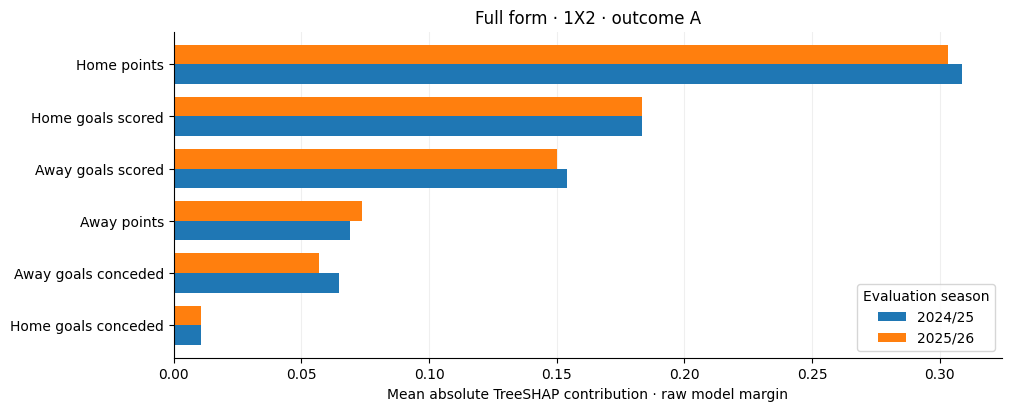

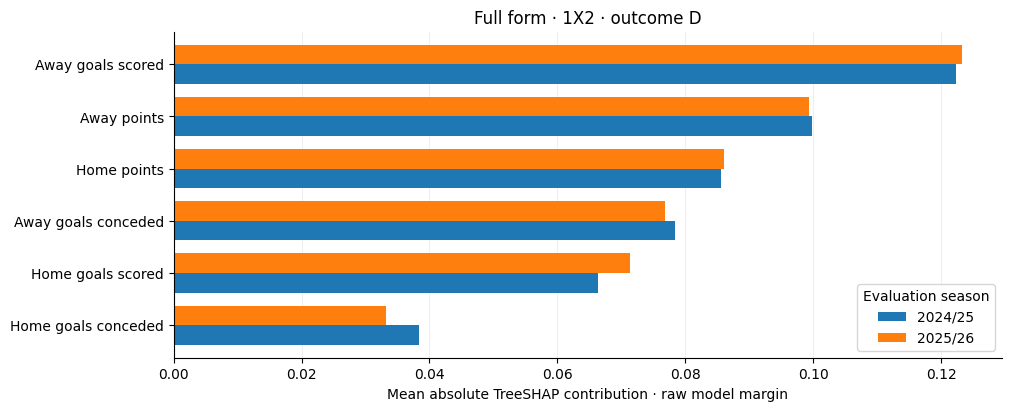

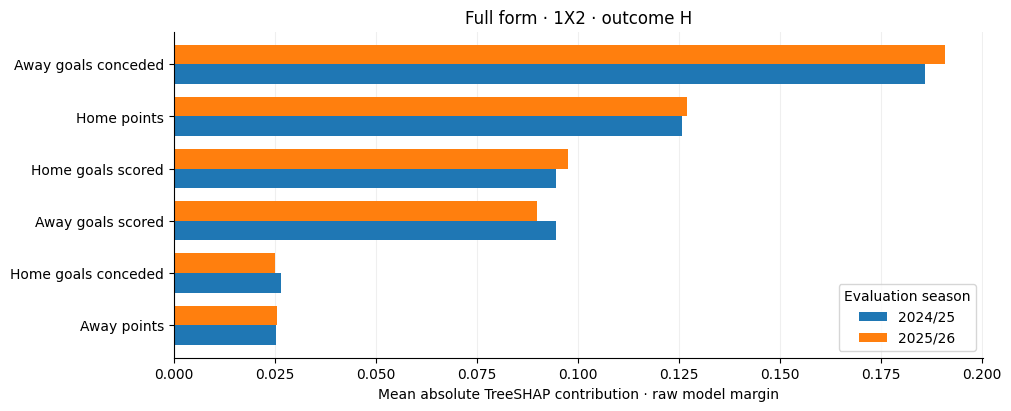

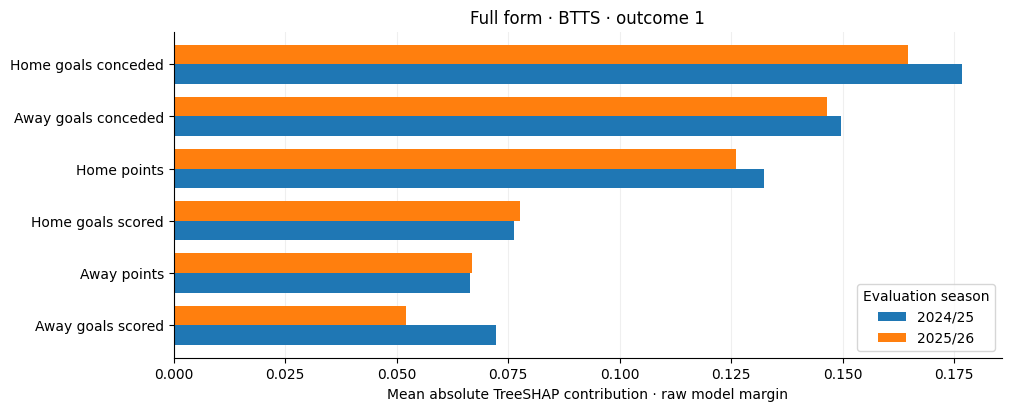

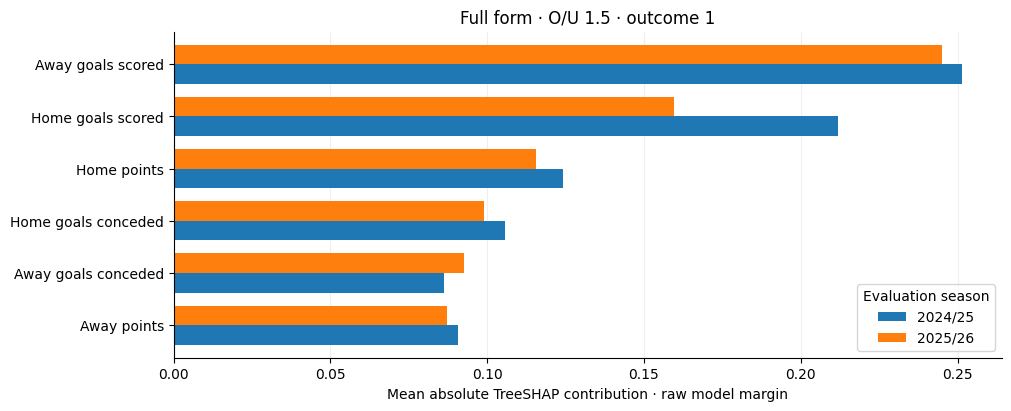

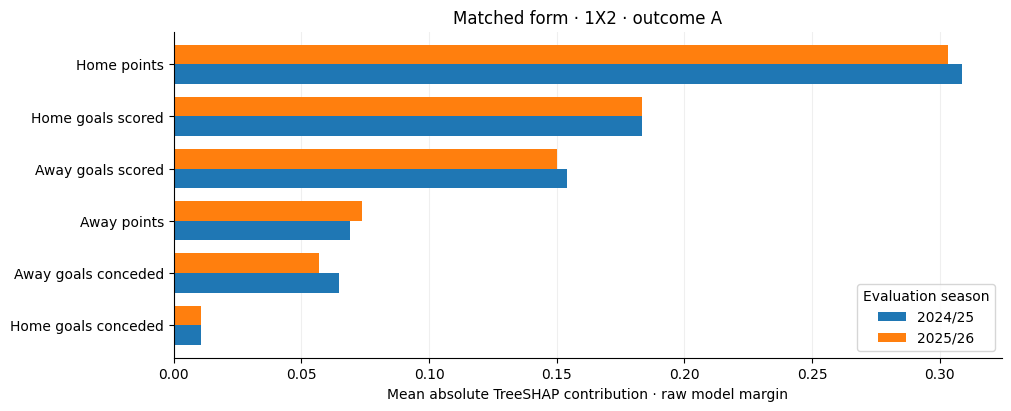

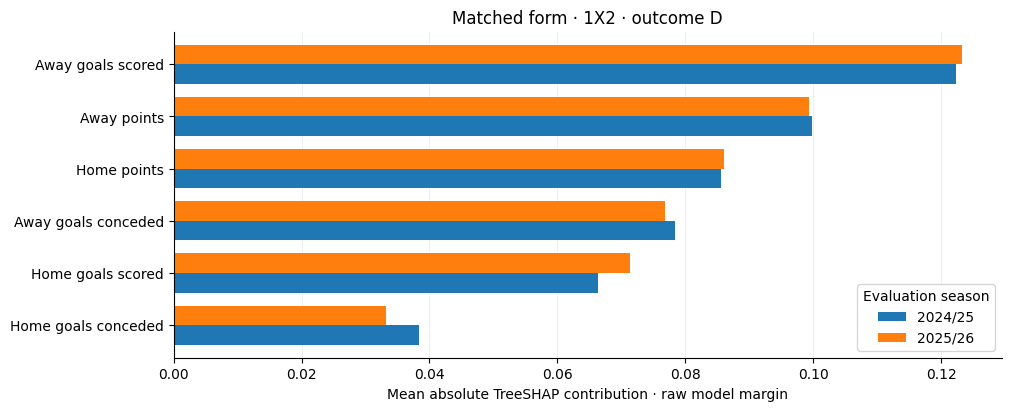

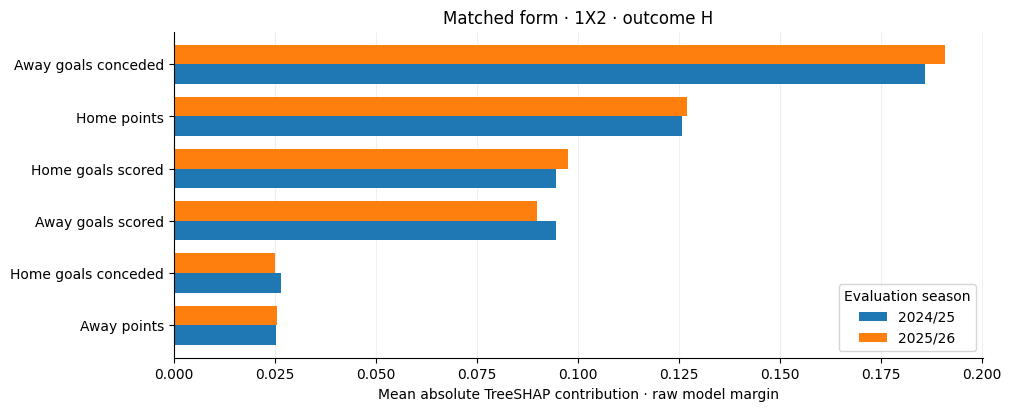

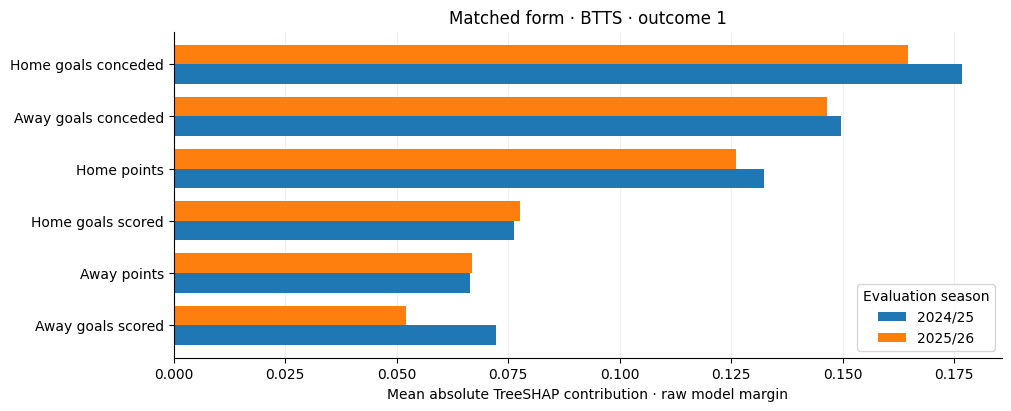

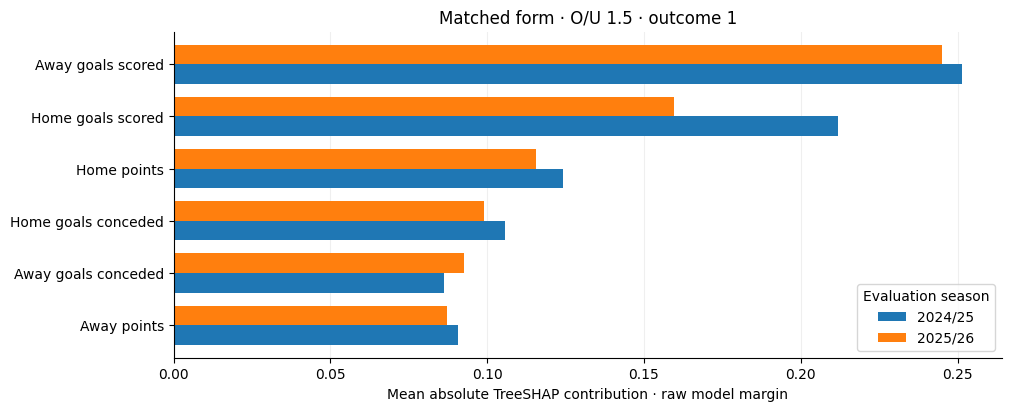

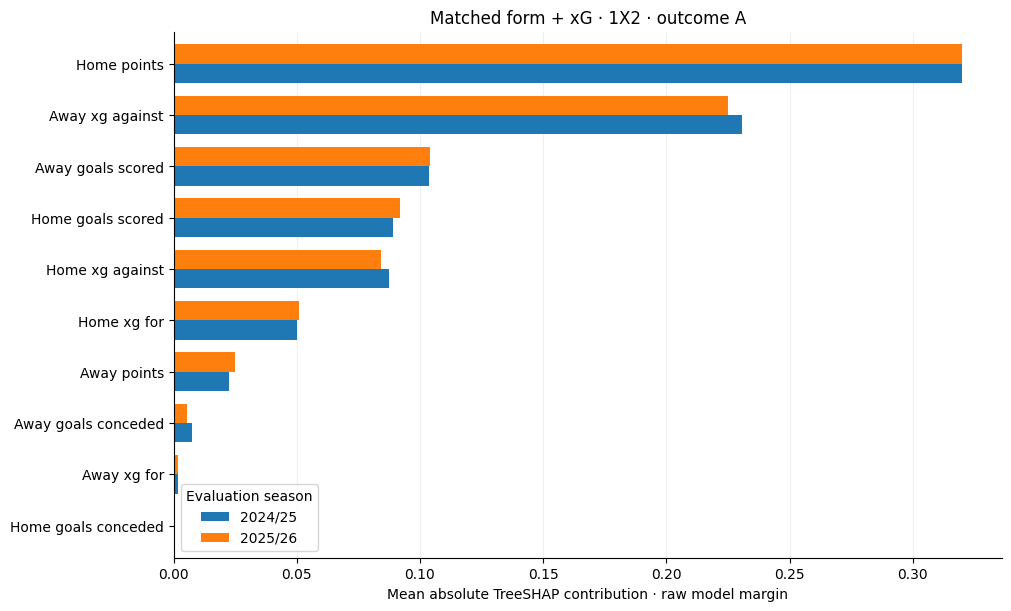

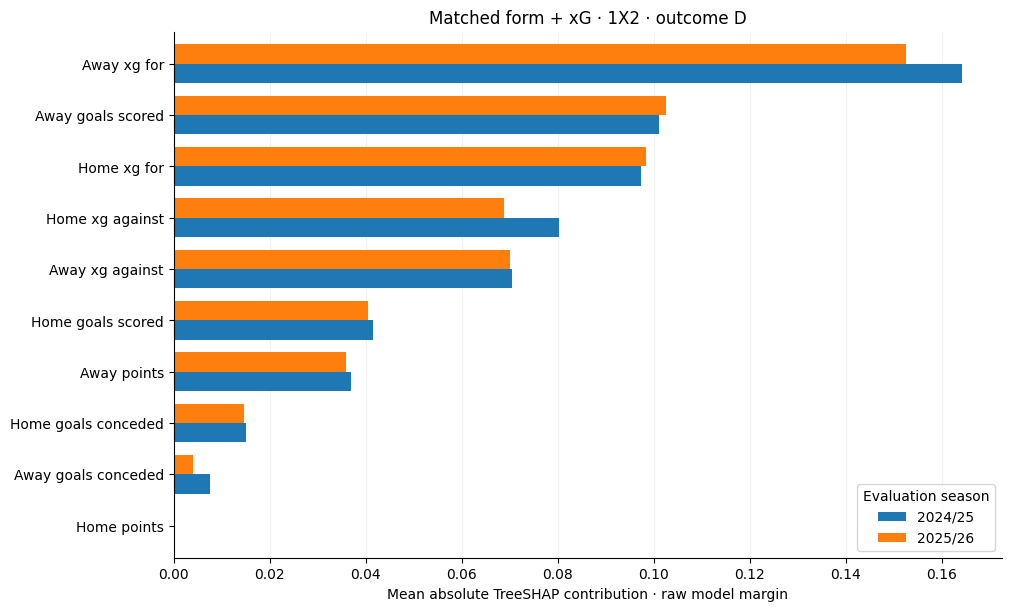

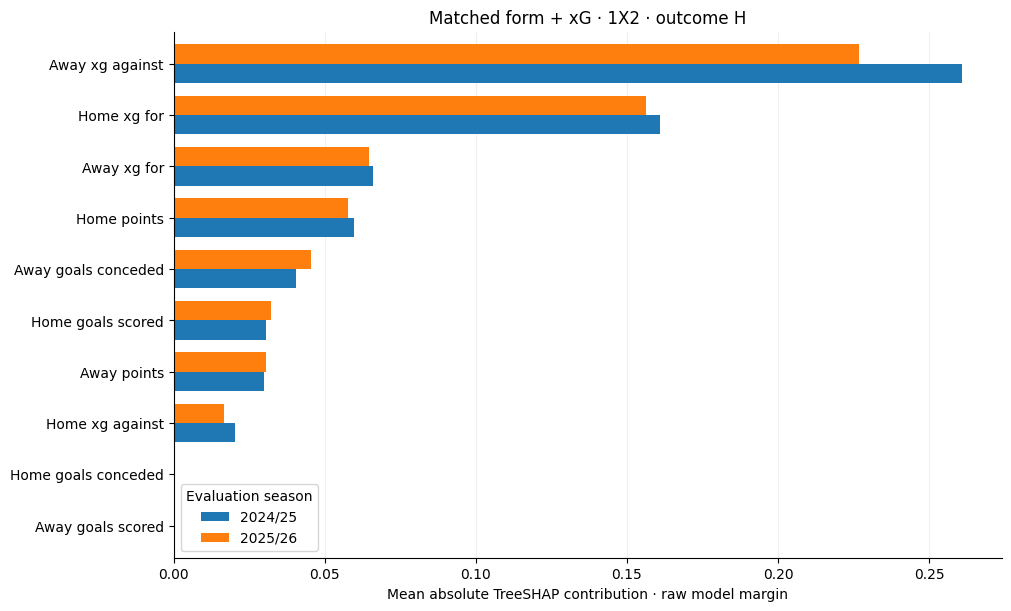

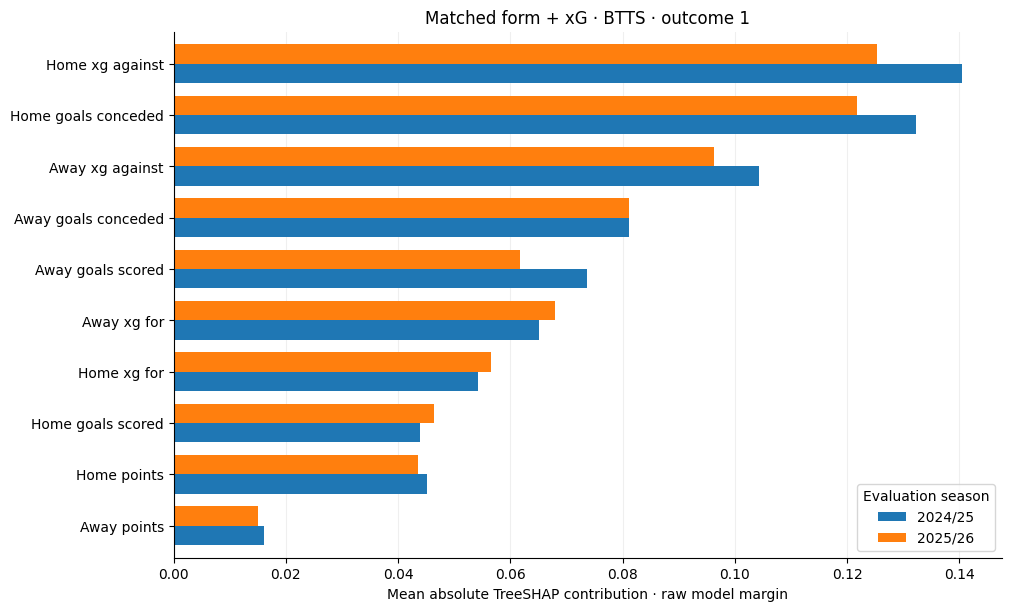

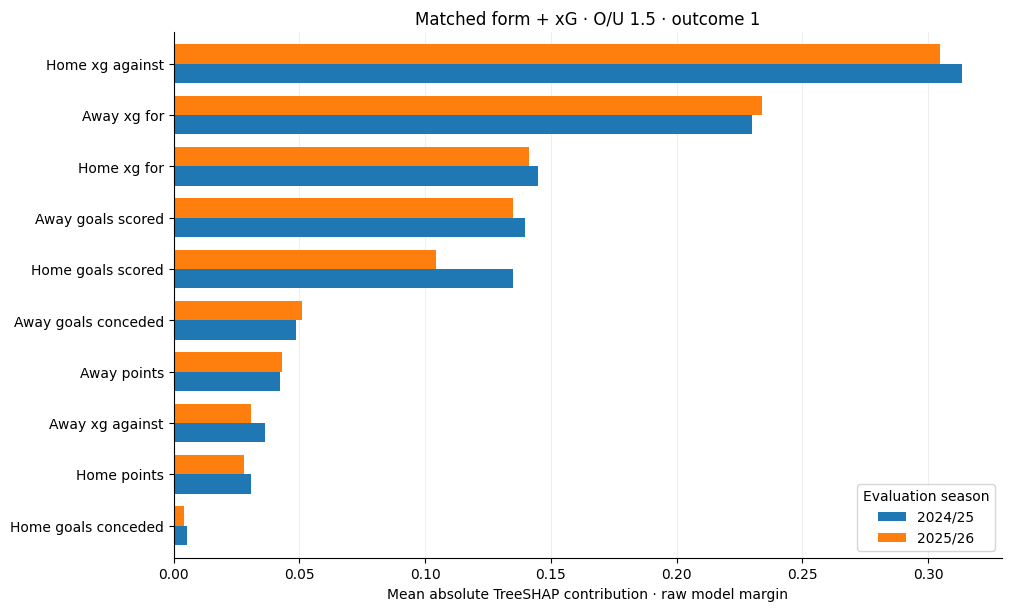

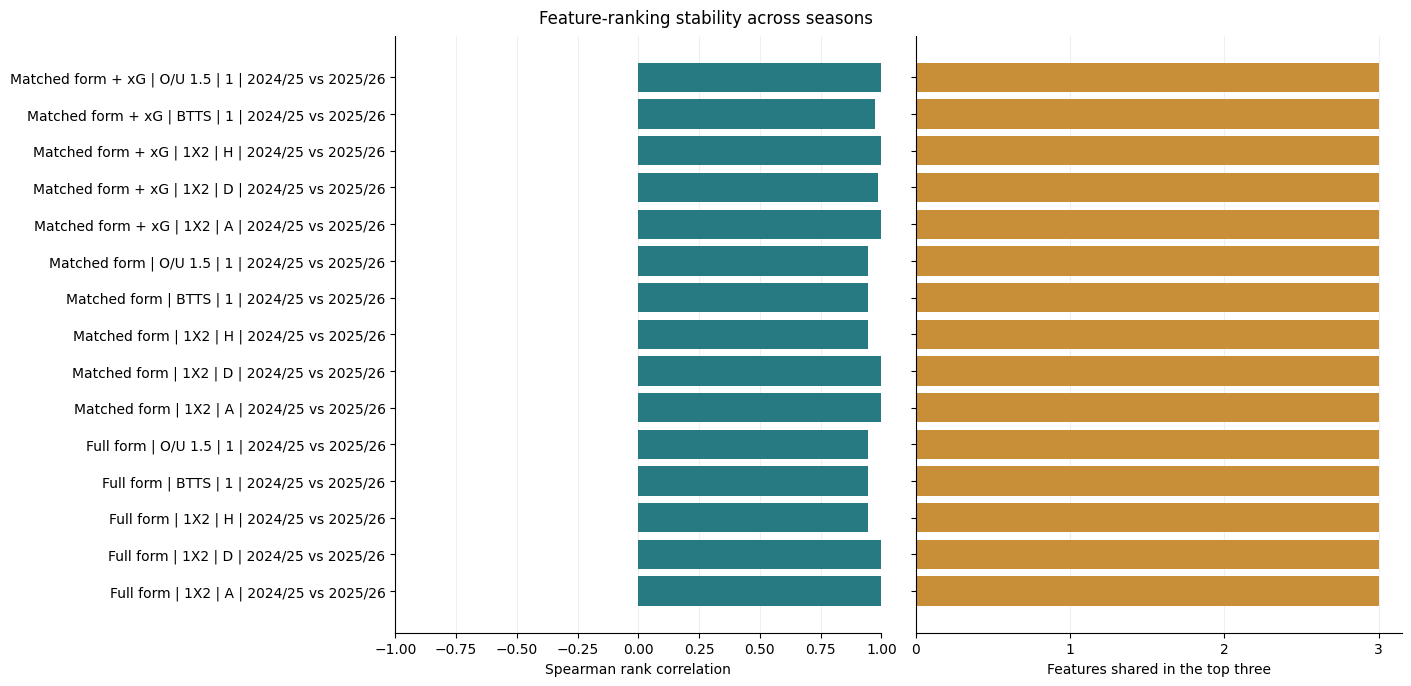

In [24]:
import matplotlib.pyplot as plt

def readable_feature(feature):
    return feature.replace("_last_3", "").replace("_", " ").capitalize()

for (arm, market, outcome), group in shap.groupby(["arm", "market", "outcome"]):
    values = group.pivot(index="feature", columns="season", values="mean_abs_shap")
    values = values.loc[values.mean(axis=1).sort_values().index]
    fig, ax = plt.subplots(figsize=(10, max(4, .5*len(values)+1)), layout="constrained")
    values.rename(index=readable_feature).plot.barh(ax=ax, width=.75)
    ax.set_title(f"{arm} · {market} · outcome {outcome}")
    ax.set_xlabel("Mean absolute TreeSHAP contribution · raw model margin")
    ax.set_ylabel("")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(title="Evaluation season")
    ax.grid(axis="x", alpha=.2)
    ax.set_axisbelow(True)
    filename = "_".join(str(part).replace("/", "-").replace(" ", "_")
                        for part in (arm, market, outcome))
    fig.savefig(out / f"shap_seasons_{filename}.png", dpi=220)
    plt.show()

if not stability.empty:
    labels = stability.apply(
        lambda r: f"{r.arm} | {r.market} | {r.outcome} | {r.season_a} vs {r.season_b}", axis=1
    )
    fig, axes = plt.subplots(1, 2, figsize=(14, max(4, .45*len(stability))),
                             layout="constrained")
    positions = np.arange(len(stability))
    axes[0].barh(positions, stability.spearman, color="#287a82")
    axes[0].set_yticks(positions, labels)
    axes[0].set_xlim(-1, 1)
    axes[0].set_xlabel("Spearman rank correlation")
    axes[1].barh(positions, stability.common_top_three, color="#c98e38")
    axes[1].set_yticks(positions, [""]*len(stability))
    axes[1].set_xticks([0, 1, 2, 3])
    axes[1].set_xlabel("Features shared in the top three")
    for ax in axes:
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="x", alpha=.2)
        ax.set_axisbelow(True)
    fig.suptitle("Feature-ranking stability across seasons")
    fig.savefig(out / "shap_stability_comparison.png", dpi=220)
    plt.show()
else:
    print("Seasonal importance plots saved. Configure two later seasons for stability comparisons.")

## Finish the research checks

These cells export fixture probabilities, plot raw xG-model reliability, estimate paired time-block intervals for xG gains, and assess revised league policies from their exports. They do not fit new calibrators. The xG ablation remains a raw-probability comparison.

Use 2-, 4-, and 6-week blocks as descriptive sensitivity analyses. Intervals condition on fitted models, feature choices and the frozen selection rules. They do not account for prior experiment selection or constitute a fresh holdout. Premier League 2025/26 is retrospective for the revised 1.5-goal experiment.


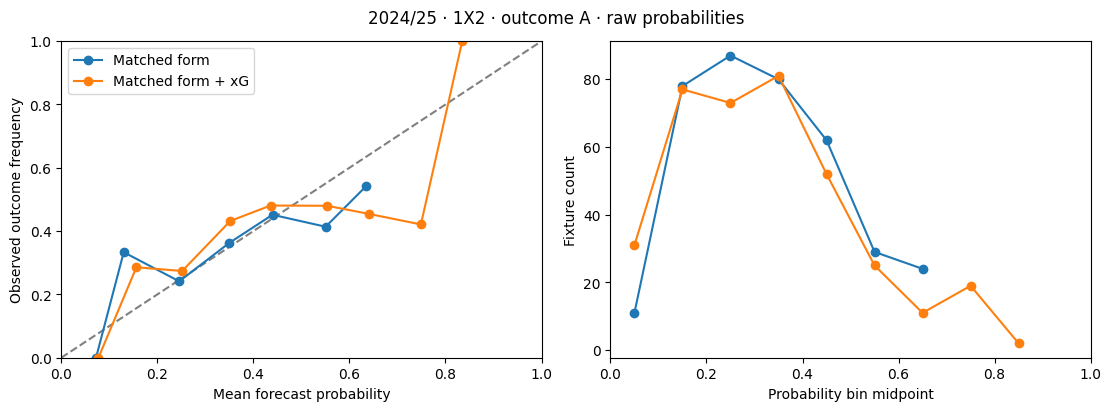

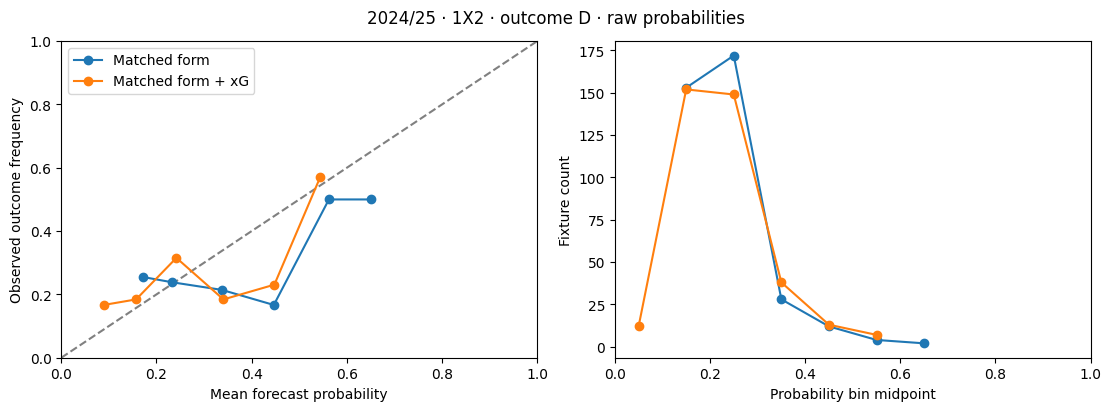

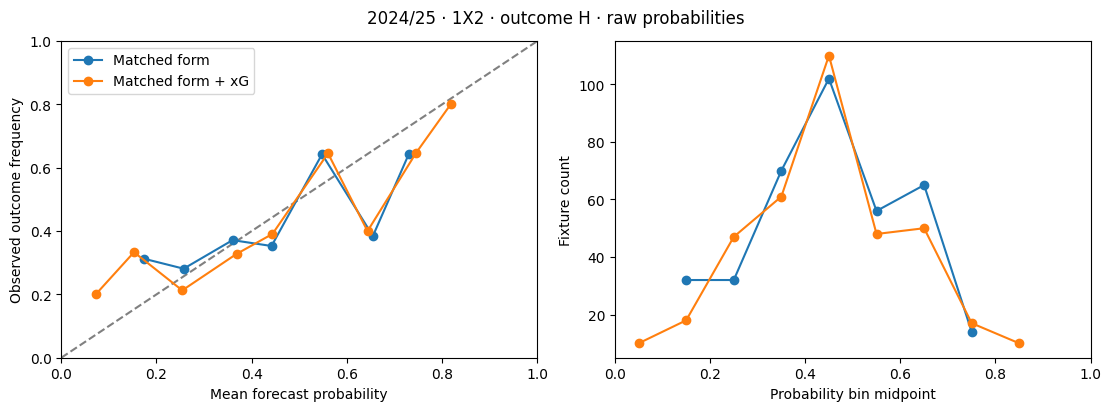

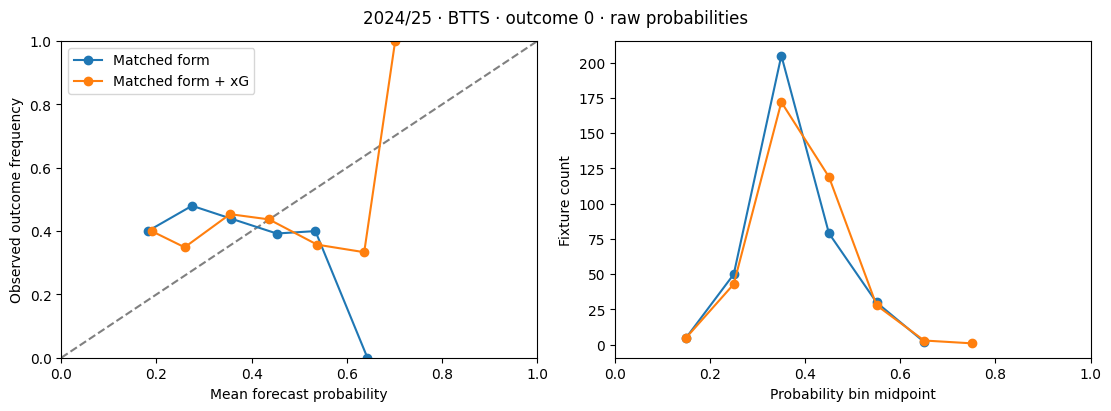

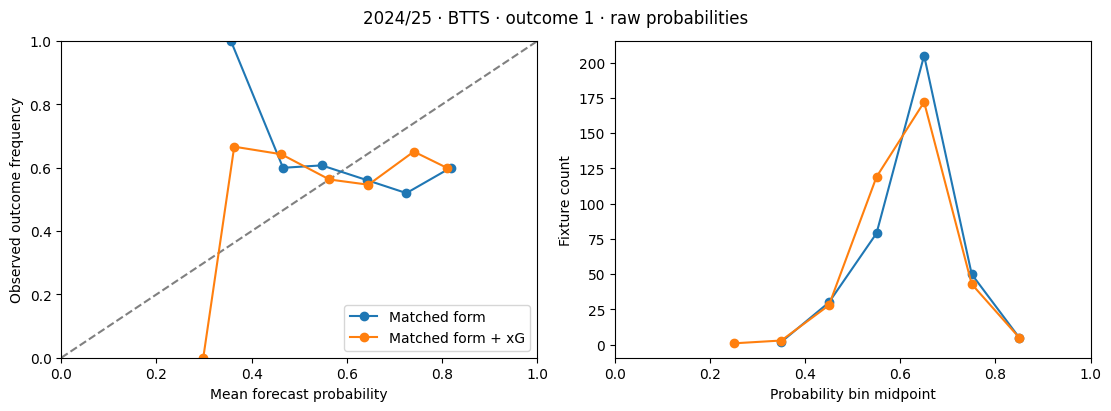

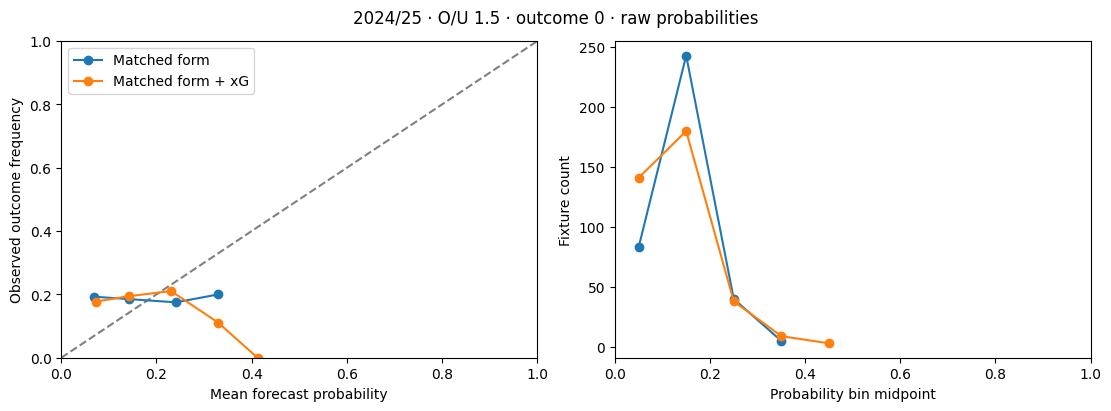

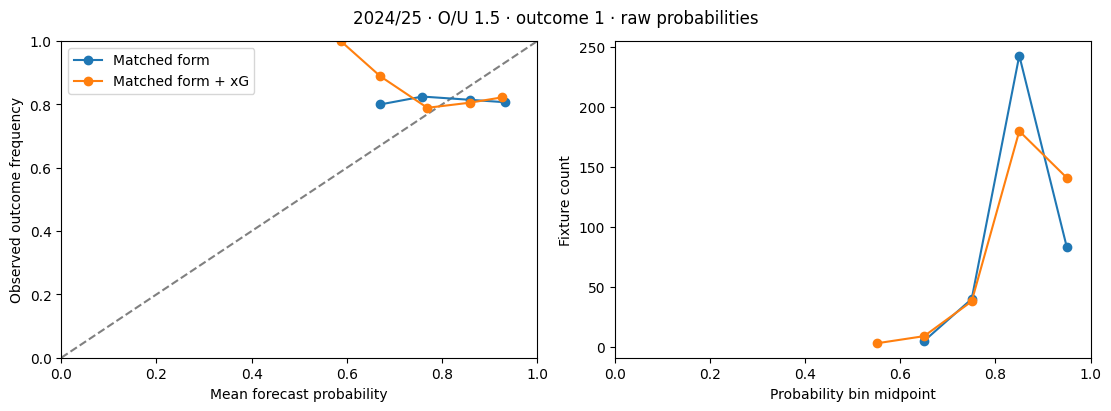

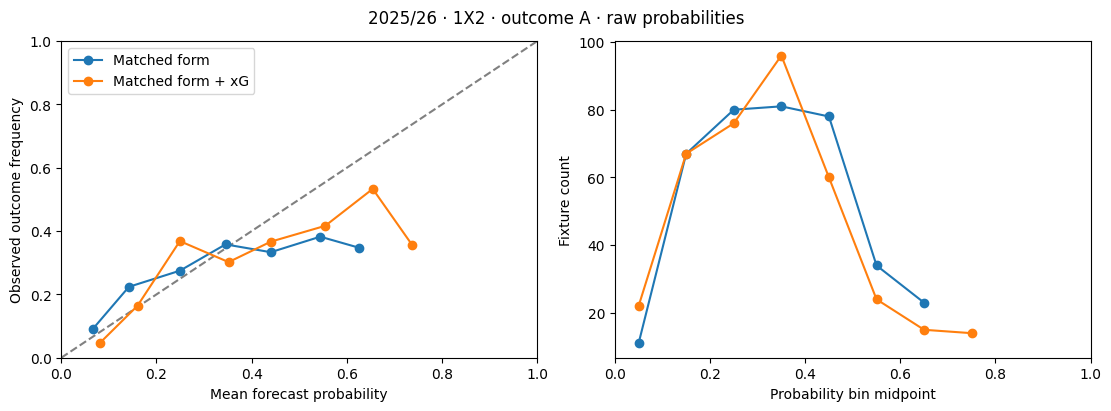

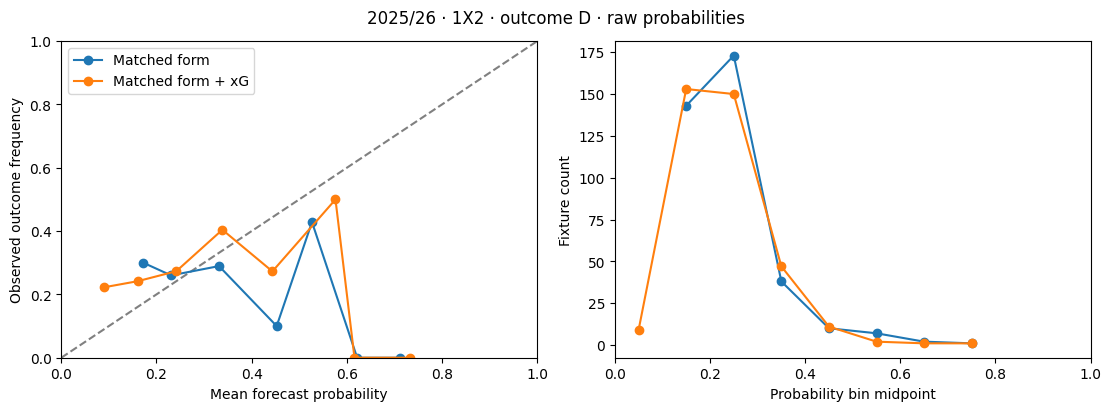

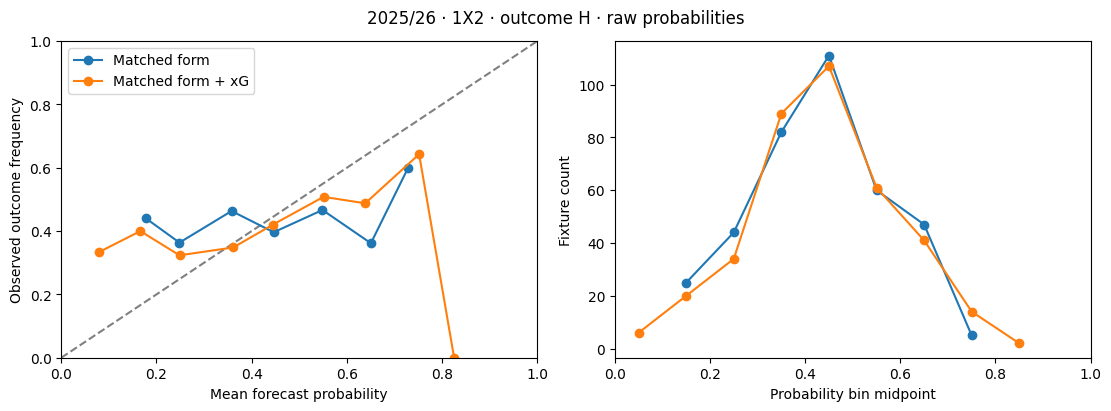

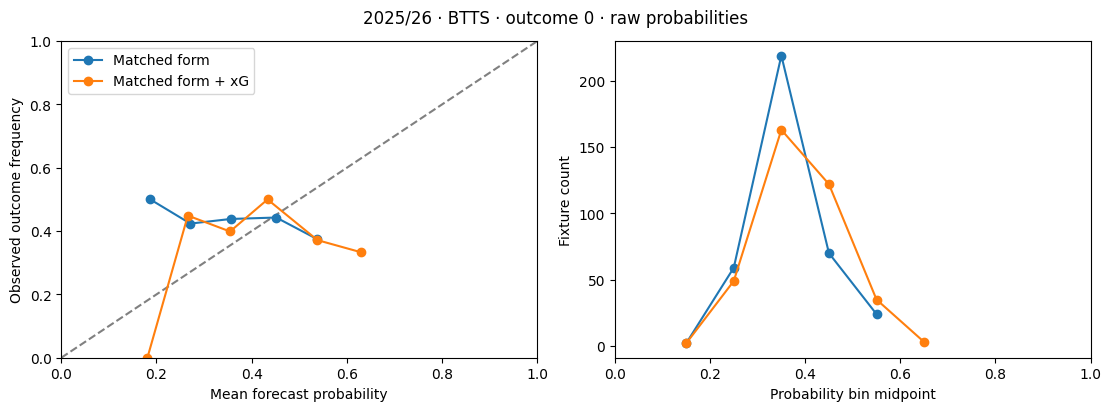

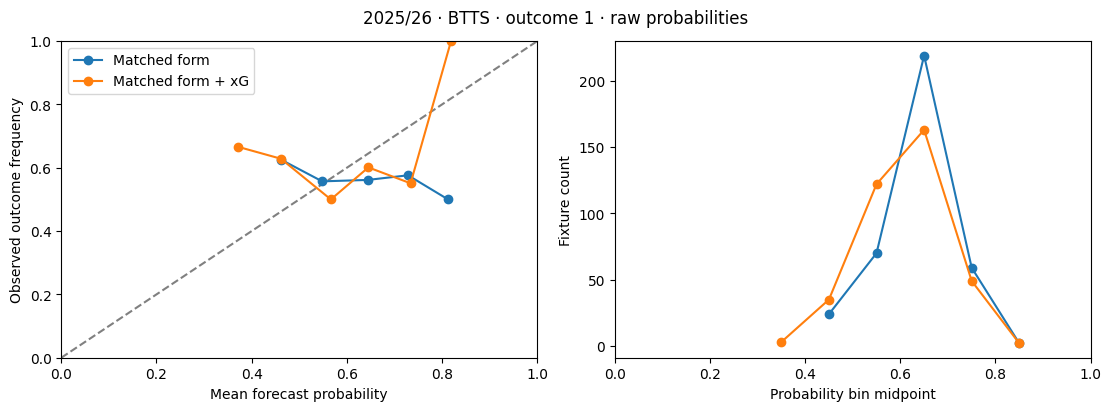

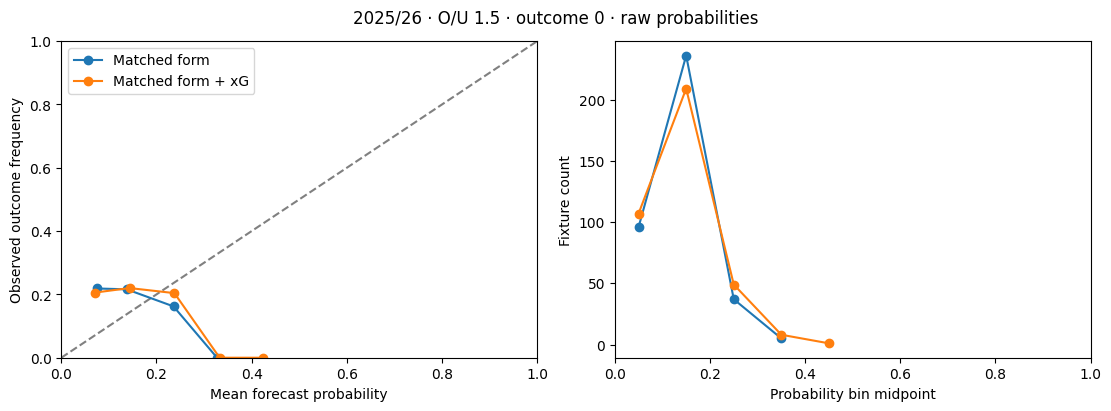

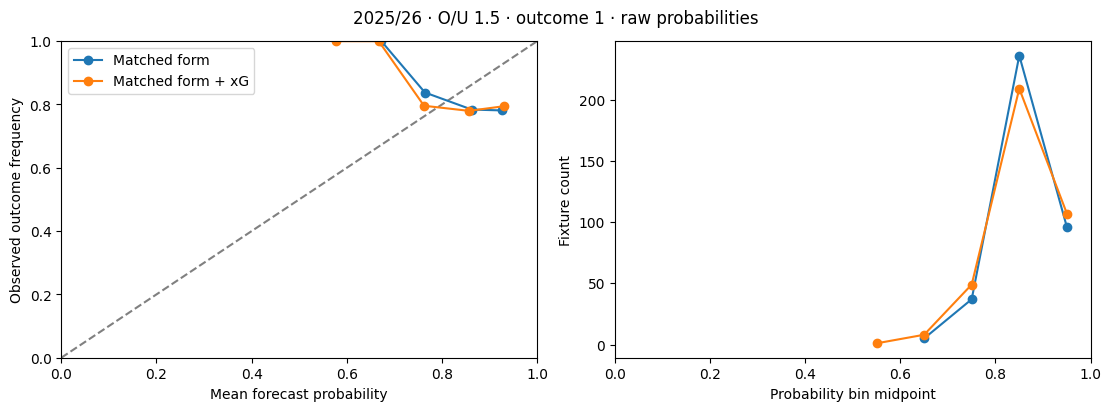

In [25]:
import matplotlib.pyplot as plt
from pathlib import Path

CHECKS = Path("research_checks")
CHECKS.mkdir(exist_ok=True)
predictions_xg = pd.concat(fixture_predictions, ignore_index=True)
prediction_keys = ["arm", "season", "market", "fixture_id", "outcome"]
assert not predictions_xg.duplicated(prediction_keys).any()
assert np.isfinite(predictions_xg.probability).all()
assert predictions_xg.probability.between(0, 1).all()
totals = predictions_xg.groupby(prediction_keys[:-1])[["probability", "observed"]].sum()
assert np.allclose(totals.probability, 1, atol=1e-6) and totals.observed.eq(1).all()
predictions_xg.to_csv(CHECKS / "fixture_probabilities.csv", index=False)

bin_rows = []
for (season, market, outcome), group in predictions_xg.loc[
    predictions_xg.arm.ne("Full form")
].groupby(["season", "market", "outcome"]):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    axes[0].plot([0, 1], [0, 1], "--", color="gray")
    for arm, arm_rows in group.groupby("arm"):
        arm_rows = arm_rows.copy()
        arm_rows["bin"] = np.minimum((arm_rows.probability*10).astype(int), 9)
        bins = arm_rows.groupby("bin").agg(
            count=("observed", "size"), mean_probability=("probability", "mean"),
            observed_frequency=("observed", "mean")).reset_index()
        bins["arm"], bins["season"], bins["market"], bins["outcome"] = arm, season, market, outcome
        bin_rows.append(bins)
        axes[0].plot(bins.mean_probability, bins.observed_frequency, marker="o", label=arm)
        axes[1].plot((bins["bin"]+.5)/10, bins["count"], marker="o", label=arm)
    axes[0].set(xlim=(0,1), ylim=(0,1), xlabel="Mean forecast probability",
                ylabel="Observed outcome frequency")
    axes[1].set(xlim=(0,1), xlabel="Probability bin midpoint", ylabel="Fixture count")
    axes[0].legend()
    fig.suptitle(f"{season} · {market} · outcome {outcome} · raw probabilities")
    safe = f"{season}_{market}_{outcome}".replace("/", "-").replace(" ", "_")
    fig.savefig(CHECKS / f"reliability_{safe}.png", dpi=220)
    plt.show()
reliability = pd.concat(bin_rows, ignore_index=True)
reliability.to_csv(CHECKS / "reliability_bins.csv", index=False)


In [26]:
def block_totals(dates, values, weeks):
    dates = pd.to_datetime(dates).reset_index(drop=True)
    origin = dates.min().normalize()
    block = ((dates-origin).dt.days // (7*weeks)).to_numpy()
    frame = pd.DataFrame(np.asarray(values))
    frame["block"] = block
    return frame.groupby("block").sum().reindex(
        range(int(block.max())+1), fill_value=0).to_numpy()

def ratio_intervals(totals, numerators, denominator, repetitions=5000):
    rng = np.random.default_rng(42)
    samples = totals[rng.integers(0, len(totals), size=(repetitions, len(totals)))].sum(axis=1)
    valid = samples[:, denominator] > 0
    if not valid.any():
        return np.full((2, len(numerators)), np.nan), 0
    ratios = samples[valid][:, numerators] / samples[valid, denominator, None]
    return np.quantile(ratios, [.025,.975], axis=0), int(valid.sum())

losses = predictions_xg.assign(
    log_loss=-predictions_xg.observed*np.log(predictions_xg.probability.clip(1e-15,1)),
    brier=(predictions_xg.probability-predictions_xg.observed)**2,
).groupby(["arm","season","market","fixture_id","kickoff"])[["log_loss","brier"]].sum().reset_index()
left = losses.loc[losses.arm.eq("Matched form")].drop(columns="arm")
right = losses.loc[losses.arm.eq("Matched form + xG")].drop(columns="arm")
keys = ["season","market","fixture_id","kickoff"]
assert set(map(tuple,left[keys].to_numpy())) == set(map(tuple,right[keys].to_numpy()))
paired = left.merge(right,on=keys,validate="one_to_one",suffixes=("_form","_xg"))
intervals = []
for (season,market), group in paired.groupby(["season","market"]):
    values = np.column_stack([
        group.log_loss_form-group.log_loss_xg,
        group.brier_form-group.brier_xg, np.ones(len(group))])
    for weeks in (2,4,6):
        totals = block_totals(group.kickoff,values,weeks)
        ci, valid = ratio_intervals(totals,[0,1],2)
        for j,metric in enumerate(("log_loss","brier")):
            intervals.append(dict(season=season,market=market,metric=metric,
                                  weeks=weeks,blocks=len(totals),fixtures=len(group),
                                  improvement=values[:,j].mean(),
                                  ci_low=ci[0,j],ci_high=ci[1,j],valid_bootstraps=valid))
xg_intervals = pd.DataFrame(intervals)
display(xg_intervals)
xg_intervals.to_csv(CHECKS / "paired_xg_intervals.csv", index=False)


,season,market,metric,weeks,blocks,fixtures,improvement,ci_low,ci_high,valid_bootstraps
0,2024/25,1X2,log_loss,2,21,371,0.041645,0.010380,0.072577,5000
1,2024/25,1X2,brier,2,21,371,0.024778,0.004644,0.044291,5000
2,2024/25,1X2,log_loss,4,11,371,0.041645,0.011055,0.077276,5000
3,2024/25,1X2,brier,4,11,371,0.024778,0.005325,0.048464,5000
4,2024/25,1X2,log_loss,6,7,371,0.041645,0.018529,0.068282,5000
5,2024/25,1X2,brier,6,7,371,0.024778,0.010130,0.043343,5000
6,2024/25,BTTS,log_loss,2,21,371,0.004258,-0.013143,0.021397,5000
7,2024/25,BTTS,brier,2,21,371,0.003925,-0.012176,0.019694,5000
8,2024/25,BTTS,log_loss,4,11,371,0.004258,-0.014728,0.022098,5000
9,2024/25,BTTS,brier,4,11,371,0.003925,-0.013015,0.020074,5000


### Revised policy uncertainty

Run the league season-ahead notebook first. Set POLICY_DIR to its export directory. This cell uses all evaluation candidates to reconstruct eligible fixture denominators, including fixtures with no pick. It pairs policies within league and fixture. The primary policy comparison reports their difference in hit rate and coverage over the same evaluation pool. The policies can choose different markets. Matched frequency performance uses each policy's own chosen fixture and market.

The retrospective top-k matched-coverage output is not bootstrapped here. It remains a descriptive sensitivity check. A league where a policy abstains has undefined hit-rate differences.


In [33]:
from pathlib import Path
import pandas as pd

pool_file = Path("evaluation_fixture_pool.csv")
picks_file = Path("evaluation_picks.csv")
if not pool_file.is_file() or not picks_file.is_file():
    print("Policy uncertainty pending. Need evaluation_fixture_pool.csv and evaluation_picks.csv.")
else:
    eligible = pd.read_csv(pool_file, parse_dates=["kickoff"])
    selected = pd.read_csv(picks_file)
    key = ["league","fixture_id"]
    assert not eligible.duplicated(key).any()
    def as_bool(series):
        values = series.astype(str).str.lower()
        if not values.isin(["true","false","1","0"]).all():
            raise ValueError("Invalid correctness field")
        return values.isin(["true","1"]).astype(int)
    selected["correct"] = as_bool(selected.correct)
    selected["baseline_correct"] = as_bool(selected.baseline_correct)
    policy_intervals, differences = [], []
    for mode in ("Validation-selected","Shared 0.625"):
        joined = eligible.copy()
        for policy, short in (("League-specific","local"),("Common","common")):
            subset = selected.loc[selected["mode"].eq(mode) & selected.policy.eq(policy)]
            assert not subset.duplicated(key).any()
            if not set(map(tuple,subset[key].to_numpy())).issubset(set(map(tuple,eligible[key].to_numpy()))):
                raise ValueError("Selected fixture missing from evaluation pool")
            subset = subset[key+["correct","baseline_correct"]].assign(pick=1)
            subset = subset.rename(columns={c:f"{short}_{c}" for c in ("correct","baseline_correct","pick")})
            joined = joined.merge(subset,on=key,how="left",validate="one_to_one")
        for column in joined.columns:
            if column.startswith(("local_","common_")):
                joined[column] = joined[column].fillna(0)
        for league in ["All leagues",*sorted(joined.league.unique())]:
            group = joined if league=="All leagues" else joined.loc[joined.league.eq(league)]
            values = group[["local_correct","local_baseline_correct","local_pick",
                            "common_correct","common_baseline_correct","common_pick"]].to_numpy()
            values = np.column_stack([values,np.ones(len(group))])
            for weeks in (2,4,6):
                totals = block_totals(group.kickoff,values,weeks)
                rng = np.random.default_rng(42)
                sample = totals[rng.integers(0,len(totals),size=(5000,len(totals)))].sum(axis=1)
                for policy,offset in (("League-specific",0),("Common",3)):
                    n = values[:,offset+2].sum()
                    valid = sample[:,offset+2]>0
                    rates = sample[valid,offset]/sample[valid,offset+2]
                    gains = (sample[valid,offset]-sample[valid,offset+1])/sample[valid,offset+2]
                    for metric,distribution,estimate in (
                        ("hit_rate",rates,values[:,offset].sum()/n if n else np.nan),
                        ("matched_baseline_difference",gains,
                         (values[:,offset].sum()-values[:,offset+1].sum())/n if n else np.nan),
                        ("coverage",sample[:,offset+2]/sample[:,6],n/len(group)),
                    ):
                        ci = np.quantile(distribution,[.025,.975]) if len(distribution) else [np.nan,np.nan]
                        policy_intervals.append(dict(mode=mode,league=league,policy=policy,weeks=weeks,
                                                      metric=metric,estimate=estimate,ci_low=ci[0],ci_high=ci[1]))
                valid = (sample[:,2]>0)&(sample[:,5]>0)
                distribution = sample[valid,0]/sample[valid,2]-sample[valid,3]/sample[valid,5]
                n1,n2 = values[:,2].sum(),values[:,5].sum()
                ci = np.quantile(distribution,[.025,.975]) if len(distribution) else [np.nan,np.nan]
                differences.append(dict(mode=mode,league=league,weeks=weeks,
                    local_minus_common_hit_rate=values[:,0].sum()/n1-values[:,3].sum()/n2 if min(n1,n2)>0 else np.nan,
                    ci_low=ci[0],ci_high=ci[1],valid_bootstraps=int(valid.sum()),
                    local_minus_common_coverage=(n1-n2)/len(group)))
    pd.DataFrame(policy_intervals).to_csv(CHECKS / "policy_intervals.csv",index=False)
    pd.DataFrame(differences).to_csv(CHECKS / "policy_differences.csv",index=False)
    display(pd.DataFrame(differences))


,mode,league,weeks,local_minus_common_hit_rate,ci_low,ci_high,valid_bootstraps,local_minus_common_coverage
0,Validation-selected,All leagues,2,0.012623,-0.018440,0.043352,5000,-0.498660
1,Validation-selected,All leagues,4,0.012623,-0.012611,0.042580,5000,-0.498660
2,Validation-selected,All leagues,6,0.012623,-0.025350,0.053118,5000,-0.498660
3,Validation-selected,LaLiga,2,NaN,NaN,NaN,0,-1.000000
4,Validation-selected,LaLiga,4,NaN,NaN,NaN,0,-1.000000
5,Validation-selected,LaLiga,6,NaN,NaN,NaN,0,-1.000000
6,Validation-selected,Premier League,2,0.000000,0.000000,0.000000,5000,0.000000
7,Validation-selected,Premier League,4,0.000000,0.000000,0.000000,5000,0.000000
8,Validation-selected,Premier League,6,0.000000,0.000000,0.000000,5000,0.000000
9,Shared 0.625,All leagues,2,0.003296,-0.021873,0.028337,5000,-0.403485


### External xG reference check

Optional published_team_xg.csv must contain fixture_id, home_xg, away_xg, source_url, provider. Use independently published team totals for specific matches with verified fixture identities. Keep the provider definition consistent. Discrepancies across different xG providers are not proof of aggregation errors. The 0.15 tolerance below is a configurable screening tolerance for rounded player sums, not a validation standard. Report the sample size, providers, absolute differences and every flag. An absent reference file leaves external validation explicitly pending.


In [34]:
reference_path = Path("published_team_xg.csv")
if not reference_path.is_file():
    print("External team-xG validation pending: published_team_xg.csv is absent.")
else:
    reference = pd.read_csv(reference_path)
    required = ["fixture_id","home_xg","away_xg","source_url","provider"]
    if not set(required).issubset(reference) or reference[required].isna().any().any():
        raise ValueError("Incomplete published reference records")
    if reference.fixture_id.duplicated().any():
        raise ValueError("Use one identified provider record per fixture")
    derived = pd.read_csv("match_xg.csv")
    comparison = reference.merge(derived,on="fixture_id",how="left",
                                 validate="one_to_one",suffixes=("_reference","_derived"))
    for side in ("home","away"):
        a = pd.to_numeric(comparison[f"{side}_xg_reference"],errors="raise")
        b = pd.to_numeric(comparison[f"{side}_xg_derived"],errors="raise")
        if not np.isfinite(a).all() or not np.isfinite(b).all() or (a<0).any():
            raise ValueError("Invalid reference values or unmatched fixtures")
        comparison[f"{side}_absolute_difference"] = abs(a-b)
    comparison["screening_flag"] = comparison[["home_absolute_difference","away_absolute_difference"]].max(axis=1)>.15
    comparison.to_csv(CHECKS / "external_xg_comparison.csv",index=False)
    display(comparison)


External team-xG validation pending: published_team_xg.csv is absent.


### Export the eligible policy pool

In the league season-ahead notebook, after its evaluation exports, run the following cell. Then rerun the policy-uncertainty cell above.


```python
pool.loc[pool.period.eq("evaluation"), ["league", "fixture_id", "kickoff"]].to_csv(
    output / "evaluation_fixture_pool.csv", index=False
)
```